# Homework 2 — Regression and Classification: Error Analysis
## Dataset: The Complete Pokémon Dataset (801 Pokémon, generations 1–7)

**Holon Institute of Technology (HIT) — Faculty of Computer Science**

| | |
|---|---|
| **Course** | Introduction to Data Science |
| **Lecturer** | Dr. Uri Itai |
| **Teaching assistant** | Hanit Ohayon Hadad |
| **Student name** | yonatan duek |
| **ID number** | 208721738 |

---
**How to read this notebook.** Every section has three layers:
1. 📘 **Theory boxes** — what each method or diagnostic measures, its assumptions and its limitations.
2. **Code + outputs** — one reproducible pipeline (one random seed, no manual steps; the only input is `pokemon.csv`). **Every metric is computed on out-of-fold predictions** from k-fold cross-validation: each Pokémon is predicted by a model that never saw it.
3. 🔎 **Interpretation boxes** — what the numbers mean, and whether an error comes from the **data**, the **model** or the **problem formulation**.

**The two prediction tasks**
* **Regression:** predict a Pokémon's **weight (kg)** from its height, base stats, type and other attributes.
* **Classification:** predict whether a Pokémon is **legendary** from its body measurements and base stats.

**Table of contents** (assignment section in brackets)
1. Dataset, data quality and preprocessing
2. Validation protocol — k-fold cross-validation and the choice of *k*
3. Regression models and their comparison [§2]
4. Regression error analysis [§1]: residuals (4.1), error by type (4.2), error vs. features (4.3), extreme errors (4.4), statistical properties (4.5), an improvement experiment (4.6), discussion (4.7)
5. Classification error analysis [§3]: problem formulation (5.1), models (5.2), confusion matrix (5.3), probabilities (5.4), errors vs. features (5.5), threshold sensitivity (5.6), discussion (5.7)
6. Final reflection [§4]

In [1]:
# ============================== Setup ==============================
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              HistGradientBoostingRegressor, HistGradientBoostingClassifier)
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.svm import SVR
from sklearn.metrics import (mean_absolute_error, mean_squared_error, median_absolute_error, r2_score,
                             accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, fbeta_score, matthews_corrcoef, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay)

try:
    from IPython.display import display
except ImportError:          # allows running the notebook as a plain script
    display = print

warnings.filterwarnings("ignore")
RANDOM_STATE = 42            # one seed everywhere -> reproducible pipeline

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 50)

# 1. Dataset, Data Quality and Preprocessing

### 1.1 Source and content
* **Source:** Kaggle — *"The Complete Pokemon Dataset"* (author: Rounak Banik), scraped from **serebii.net**. File used: `pokemon.csv`.
* **Rows:** the 801 Pokémon of generations 1–7 (one row per species).
* **Why this dataset fits the assignment:** it contains a **continuous, strongly skewed target** (weight: 0.1 kg to 999.9 kg — ideal for studying heteroscedasticity and heavy-tailed errors), a **rare binary target** (legendary: < 10% — ideal for FP/FN and threshold analysis), and a natural **"sector" variable** (the Pokémon's primary type) to look for groups with high error rates.

| Group | Features | Meaning / scale |
|---|---|---|
| Body | `height_m`, `weight_kg` | metres, kilograms |
| Base stats (6) | `hp`, `attack`, `defense`, `sp_attack`, `sp_defense`, `speed` | battle stats, 1–255; `base_total` is their sum |
| Game-design attributes | `capture_rate`, `base_egg_steps`, `base_happiness`, `experience_growth`, `percentage_male` | how hard to catch / hatch / level up; share of males |
| Categories | `type1`, `type2`, `generation`, `is_legendary` | 18 types; generation 1–7; target of the classifier |
| Type effectiveness (18) | `against_bug` … `against_water` | damage multiplier taken from each attack type — a deterministic function of the types |
| Identifiers / text | `name`, `japanese_name`, `pokedex_number`, `classfication`, `abilities` | not used as features |

### 1.2 Structural analysis — columns, types, missing values, inconsistencies

In [2]:
DATA_FILE = "pokemon.csv"         # Kaggle: "The Complete Pokemon Dataset" (Rounak Banik)
if not os.path.exists(DATA_FILE) and os.path.exists(os.path.join("data", DATA_FILE)):
    DATA_FILE = os.path.join("data", DATA_FILE)
df_full = pd.read_csv(DATA_FILE)
print(f"Loaded {df_full.shape[0]:,} Pokémon x {df_full.shape[1]} columns")

STATS = ["hp", "attack", "defense", "sp_attack", "sp_defense", "speed"]
AGAINST = [c for c in df_full.columns if c.startswith("against_")]
col_types = pd.Series({c: ("numeric" if pd.api.types.is_numeric_dtype(df_full[c]) else "text") for c in df_full.columns})
print("Column types in the raw file:", col_types.value_counts().to_dict())

missing = df_full.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False).to_frame("n_missing")
missing["%"] = 100 * missing.n_missing / len(df_full)
display(missing)

bad_cr = ~df_full.capture_rate.astype(str).str.fullmatch(r"\d+")
print("Non-numeric capture_rate values:")
display(df_full.loc[bad_cr, ["name", "capture_rate", "is_legendary"]])
print("Pokémon without height/weight:", ", ".join(df_full.loc[df_full.weight_kg.isna(), "name"]))
print(f"base_total == sum of the six stats for {100 * (df_full[STATS].sum(axis=1) == df_full.base_total).mean():.1f}% of rows")
print("Missing percentage_male (= genderless) vs. legendary status:")
display(pd.crosstab(df_full.percentage_male.isna().rename("genderless"), df_full.is_legendary.rename("is_legendary")))
print(f"Fully duplicated rows: {df_full.duplicated().sum()};  duplicated names: {df_full.name.duplicated().sum()}")

Loaded 801 Pokémon x 41 columns
Column types in the raw file: {'numeric': 34, 'text': 7}


,n_missing,%
type2,384,47.940
percentage_male,98,12.235
height_m,20,2.497
weight_kg,20,2.497


Non-numeric capture_rate values:


,name,capture_rate,is_legendary
773,Minior,30 (Meteorite)255 (Core),0


Pokémon without height/weight: Rattata, Raticate, Raichu, Sandshrew, Sandslash, Vulpix, Ninetales, Diglett, Dugtrio, Meowth, Persian, Geodude, Graveler, Golem, Grimer, Muk, Exeggutor, Marowak, Hoopa, Lycanroc
base_total == sum of the six stats for 100.0% of rows
Missing percentage_male (= genderless) vs. legendary status:


is_legendary,0,1
genderless,,
False,696,7
True,35,63


Fully duplicated rows: 0;  duplicated names: 0


🔎 **What the structure tells us — the missing values are not random**
* **41 columns: 34 numeric, 7 text.** One "text" column is a number in disguise: `capture_rate` is stored as a string because of a single row — **Minior**, whose value is `"30 (Meteorite)255 (Core)"` (two forms, two values, written into one cell). A **data-entry problem**.
* **`height_m` and `weight_kg` are missing for the same 20 Pokémon** — Rattata, Raichu, Sandshrew, Vulpix, Diglett, Meowth, Geodude, Grimer, Exeggutor, Marowak… (all Pokémon with an **Alolan form**), plus Hoopa and Lycanroc. These are exactly the species that have **several forms with different sizes**: the scraper could not pick one value. The missingness depends on a property of the Pokémon → *missing not at random*.
* **`percentage_male` is missing for 98 Pokémon** — these are **genderless** Pokémon, and **63 of the 98 are legendary** (63 of the 70 legendaries overall). The "missing" value is itself highly informative.
* **`type2` is missing for 384 Pokémon (48%)**: not a gap — they simply have a single type.
* **`base_total` equals the sum of the six base stats in 100% of the rows** → including it next to the stats would create **perfect multicollinearity**. The 18 `against_*` columns are determined by the type(s) → redundant with `type1`/`type2`.
* No duplicated rows and no duplicated names.

### 1.3 Preprocessing decisions
1. **Rows:** drop the 20 Pokémon without height/weight (they have no regression target; imputing a target would invent the answer). Remaining: **781 Pokémon**.
2. **`capture_rate` → numeric**; for Minior we keep the first number (30). One row out of 781, documented.
3. **`percentage_male`:** keep it (median-imputed inside the pipeline) **and** add the explicit flag `is_genderless`, so the information carried by the missingness is not lost.
4. **`type2`:** missing → category `"none"`, plus a flag `has_type2`.
5. **Excluded features:** `base_total` (exact linear combination of the stats), `against_*` (deterministic in the types), identifiers and free text.
6. **Feature sets.** Regression (same set for *every* model): height, 6 stats, 5 game-design attributes, `is_genderless`, `has_type2`, `generation`, `is_legendary` + one-hot `type1`/`type2`. Classification: body + 6 stats + `has_type2` + `generation` + types (the reason for excluding the game-design attributes is shown in Section 5.1).
7. **Scaling and imputation are fitted inside each training fold** (scikit-learn `Pipeline`), so no information from a validation fold leaks into training.

In [3]:
# ---- Build the analysis table ----
df = df_full.dropna(subset=["weight_kg"]).copy()                     # (1) no target -> cannot be used
df["capture_rate"] = pd.to_numeric(df.capture_rate.astype(str).str.extract(r"(\d+)")[0])   # (2) "30 (Meteorite)255 (Core)" -> 30
df["is_genderless"] = df.percentage_male.isna().astype(int)          # (3) informative missingness -> explicit flag
df["has_type2"] = df.type2.notna().astype(int)                       # (4) no second type is a value, not a gap
df["type2"] = df.type2.fillna("none")
df = df.reset_index(drop=True)

REG_TARGET, CLF_TARGET, GROUP_COL = "weight_kg", "is_legendary", "type1"
REG_NUM = (["height_m"] + STATS + ["capture_rate", "base_egg_steps", "base_happiness", "experience_growth",
                                   "percentage_male", "is_genderless", "has_type2", "generation", "is_legendary"])
CLF_NUM = ["height_m", "weight_kg"] + STATS + ["has_type2", "generation"]
SHORTCUTS = ["capture_rate", "base_egg_steps", "base_happiness", "experience_growth", "is_genderless"]
CAT = ["type1", "type2"]
ID_COLS = ["name", "classfication"]          # (sic) column name in the original file

n = len(df)
print(f"Analysis table: {n} Pokémon")
print(f"Regression: target '{REG_TARGET}', {len(REG_NUM)} numeric + {len(CAT)} categorical features")
print(f"Classification: target '{CLF_TARGET}' ({df[CLF_TARGET].sum()} positives = {df[CLF_TARGET].mean():.1%}), "
      f"{len(CLF_NUM)} numeric + {len(CAT)} categorical features")
display(df[REG_NUM].describe().T[["mean", "std", "min", "50%", "max"]])

Analysis table: 781 Pokémon
Regression: target 'weight_kg', 16 numeric + 2 categorical features
Classification: target 'is_legendary' (69 positives = 8.8%), 10 numeric + 2 categorical features


,mean,std,min,50%,max
height_m,1.164,1.080,0.100,1.000,14.500
hp,69.149,26.622,1.000,65.000,255.000
attack,77.694,32.224,5.000,75.000,185.000
defense,73.003,30.806,5.000,70.000,230.000
sp_attack,71.633,32.184,10.000,65.000,194.000
sp_defense,71.018,28.009,20.000,66.000,230.000
speed,66.279,28.904,5.000,65.000,180.000
capture_rate,97.854,75.877,3.000,60.000,255.000
base_egg_steps,"7,224.379","6,574.370","1,280.000","5,120.000","30,720.000"
base_happiness,65.205,19.796,0.000,70.000,140.000


### 1.4 The two targets

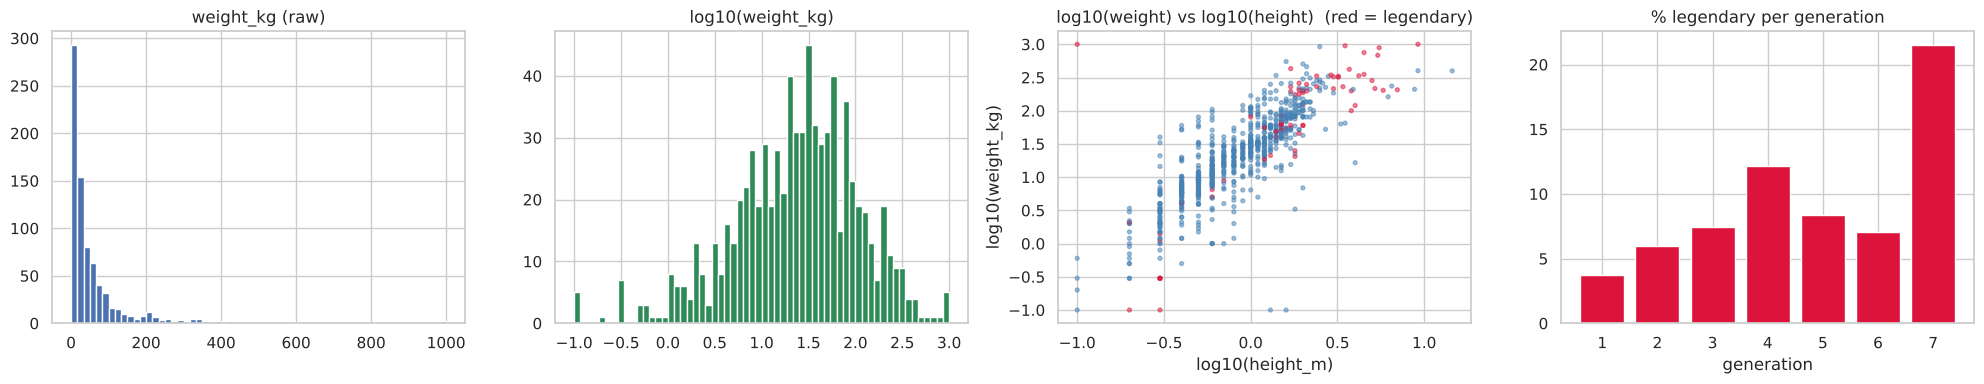

,skewness,excess kurtosis,median,max / median
weight_kg,4.862,31.525,27.300,36.626
log10(weight_kg),-0.544,0.667,1.436,NaN


log-log fit: log10(weight) = 1.77 * log10(height) + 1.45   (r = 0.81)
Pokémon with weight exactly 999.9 kg: Cosmoem, Celesteela


generation,1,2,3,4,5,6,7
n_legendary,5.000,6.000,10.000,13.000,13.000,5.000,17.000
share,0.038,0.060,0.074,0.121,0.083,0.070,0.215


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].hist(df.weight_kg, bins=60); axes[0].set_title("weight_kg (raw)")
axes[1].hist(np.log10(df.weight_kg), bins=60, color="seagreen"); axes[1].set_title("log10(weight_kg)")
axes[2].scatter(np.log10(df.height_m), np.log10(df.weight_kg), s=8, alpha=.5,
                c=np.where(df.is_legendary == 1, "crimson", "steelblue"))
axes[2].set(title="log10(weight) vs log10(height)  (red = legendary)", xlabel="log10(height_m)", ylabel="log10(weight_kg)")
leg = df.groupby("generation").is_legendary.agg(["sum", "mean"])
axes[3].bar(leg.index, 100 * leg["mean"], color="crimson"); axes[3].set(title="% legendary per generation", xlabel="generation")
plt.tight_layout(); plt.show()

shape = pd.DataFrame({"skewness": [stats.skew(df.weight_kg), stats.skew(np.log10(df.weight_kg))],
                      "excess kurtosis": [stats.kurtosis(df.weight_kg), stats.kurtosis(np.log10(df.weight_kg))],
                      "median": [df.weight_kg.median(), np.log10(df.weight_kg).median()],
                      "max / median": [df.weight_kg.max() / df.weight_kg.median(), np.nan]},
                     index=["weight_kg", "log10(weight_kg)"])
display(shape)
slope, intercept, r, *_ = stats.linregress(np.log10(df.height_m), np.log10(df.weight_kg))
print(f"log-log fit: log10(weight) = {slope:.2f} * log10(height) + {intercept:.2f}   (r = {r:.2f})")
print(f"Pokémon with weight exactly 999.9 kg: {', '.join(df.loc[df.weight_kg == 999.9, 'name'])}")
display(leg.rename(columns={"sum": "n_legendary", "mean": "share"}).T)

🔎 **What the targets look like**
* **Weight is extremely right-skewed:** skewness 4.86, excess kurtosis 31.5; the median Pokémon weighs 27.3 kg, the heaviest **36.6×** more. After `log10` the distribution is almost symmetric (skewness −0.54, kurtosis 0.67). Any model trained on raw kilograms will be dominated, in squared-error terms, by a handful of very heavy Pokémon.
* **Weight follows a power law of height:** $\log_{10}(w) = 1.77\,\log_{10}(h) + 1.45$ ($r = 0.81$). The exponent is **1.77, not 3**: Pokémon are not geometrically similar — tall Pokémon tend to be slender (snakes, dragons). The scatter around the line is large (a vertical spread of ~2 orders of magnitude at a given height): weight is not determined by size alone.
* **Two Pokémon weigh exactly 999.9 kg** (Cosmoem and Celesteela) — the maximum weight value used by the games. A **ceiling (censoring) artifact**: their "true" weight in the story is not recorded.
* **Legendary is rare and not stable over time:** 69 of 781 (8.8%). The share grows from 3.8% in generation 1 to **21.5% in generation 7** (17 legendaries, including the Ultra Beasts and the Tapus). The definition of "legendary" changed across generations — a possible **concept drift** that we will meet again in the classification errors.

# 2. Validation Protocol — k-fold Cross-Validation and the Choice of *k*
📘 **k-fold cross-validation.** The data are split into $k$ folds; each fold is predicted by a model trained on the other $k-1$. The result is an **out-of-fold (OOF) prediction for every row** — we use these for *all* error analyses below — and $k$ estimates of the test error.

**How $k$ affects the estimate**
* **Bias:** each model is trained on a fraction $(k-1)/k$ of the data. With a small $k$ the training sets are much smaller than the full dataset, so the CV error is **pessimistically biased** (a model trained on 520 Pokémon is worse than one trained on 781).
* **Variance:** with a large $k$ the training sets overlap almost completely, so the $k$ fold errors are strongly correlated and the estimate can be noisy; each validation fold is also tiny, so the **error of a single fold** becomes very unstable (one extreme Pokémon in a fold of 39 rows dominates it).
* **Cost:** $k$ model fits; leave-one-out ($k = n$) is the extreme.

We measure all three on our data: for $k \in \{3,5,10,20\}$ and two models, we run 5 different random shuffles and report the mean CV-RMSE (bias), the sd across folds, the **sd of the CV estimate across shuffles** (how reproducible the estimate is), and the runtime.

In [5]:
# ---- Shared building blocks ----
def make_preprocessor(num_cols, cat_cols=CAT):
    """Median imputation + standardization (numeric), one-hot (categorical).
    Lives INSIDE the pipeline -> re-fitted on the training folds only (no leakage into validation folds)."""
    num = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])

def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

def cv_regression(estimator, num_cols, cv, data=None, target=REG_TARGET):
    """Manual k-fold loop -> out-of-fold prediction for every row + per-fold train/validation metrics."""
    data = df if data is None else data
    X, y = data[num_cols + CAT], data[target]
    pipe = Pipeline([("prep", make_preprocessor(num_cols)), ("model", estimator)])
    oof, rows = np.zeros(len(y)), []
    for f, (tr, va) in enumerate(cv.split(X)):
        t0 = time.perf_counter()
        m = clone(pipe).fit(X.iloc[tr], y.iloc[tr])
        p_tr, p_va = m.predict(X.iloc[tr]), m.predict(X.iloc[va])
        oof[va] = p_va
        rows.append({"fold": f, "train_RMSE": rmse(y.iloc[tr], p_tr), "val_RMSE": rmse(y.iloc[va], p_va),
                     "val_R2": r2_score(y.iloc[va], p_va), "seconds": time.perf_counter() - t0})
    return oof, pd.DataFrame(rows)

# ---- Choice of k: bias of the estimate, its variability, and its cost ----
k_rows = []
for k in [3, 5, 10, 20]:
    for name, est in [("LinearRegression", LinearRegression()),
                      ("DecisionTree", DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=RANDOM_STATE))]:
        per_seed, fold_sd, t0 = [], [], time.perf_counter()
        for seed in range(5):                                   # 5 different shuffles of the same k
            _, folds = cv_regression(est, REG_NUM, KFold(k, shuffle=True, random_state=seed))
            per_seed.append(folds.val_RMSE.mean()); fold_sd.append(folds.val_RMSE.std())
        k_rows.append({"k": k, "model": name, "train size": int(n * (k - 1) / k),
                       "mean CV-RMSE": np.mean(per_seed), "sd across folds": np.mean(fold_sd),
                       "sd of the CV estimate across shuffles": np.std(per_seed),
                       "seconds (5 shuffles)": time.perf_counter() - t0})
k_table = pd.DataFrame(k_rows).set_index(["model", "k"]).sort_index()
display(k_table)

K_FOLDS = 10
kf = KFold(K_FOLDS, shuffle=True, random_state=RANDOM_STATE)
skf = StratifiedKFold(K_FOLDS, shuffle=True, random_state=RANDOM_STATE)
print(f"Chosen: k = {K_FOLDS} -> {n // K_FOLDS} Pokémon per validation fold; "
      f"stratified folds hold ≈ {df[CLF_TARGET].sum() / K_FOLDS:.0f} legendary Pokémon each")

train size  mean CV-RMSE  sd across folds  sd of the CV estimate across shuffles  seconds (5 shuffles)
model            k                                                                                                         
DecisionTree     3          520        83.757           20.931                                  1.838                 0.381
                 5          624        82.170           26.883                                  0.989                 0.624
                 10         702        76.053           32.244                                  1.897                 1.329
                 20         741        70.301           40.226                                  2.165                 2.562
LinearRegression 3          520        78.914           15.658                                  2.113                 0.355
                 5          624        77.195           23.677                                  0.980                 0.633
                 10         702        74.324           29.814                                  0.984                 1.307
                 20         741        71.361           36.124                                  0.715                 2.546

Chosen: k = 10 -> 78 Pokémon per validation fold; stratified folds hold ≈ 7 legendary Pokémon each


🔎 **Choosing k = 10**
* **Bias is clearly visible:** the mean CV-RMSE of linear regression falls from 78.9 (k = 3, 520 training rows) to 77.2 (k = 5), **74.3 (k = 10)** and 71.4 (k = 20); the decision tree falls from 83.8 to 70.3. With only 781 rows, every extra training example matters — small $k$ underestimates how good the models really are.
* **The sd across folds grows with k** (15.7 → 36.1 for the linear model): with 39 Pokémon per fold at k = 20, a fold that happens to contain Cosmoem or Celesteela has a huge RMSE. This is the *fold-level* noise, not the noise of the final estimate.
* **The reproducibility of the estimate** (sd across shuffles) is ≈ 1 for k = 5 and k = 10 for both models; k = 3 is the least stable (2.1 for the linear model), and k = 20 is unstable for the tree (2.2).
* **Cost is negligible** at this size (≈ 1 s for 5 shuffles at k = 10).
* **Decision: k = 10.** The dataset is small, so the bias argument dominates; k = 10 keeps 90% of the data for training (702 rows), gives a reproducible estimate, and still leaves 78 Pokémon per validation fold. For classification we use **stratified** 10-fold, so each fold contains ≈ 7 of the 69 legendaries — without stratification some folds could contain almost none, making fold-level AUC/F1 meaningless.
* **Caveat for the whole notebook:** 7 positives per fold is small → fold-level classification metrics will have a large sd; we report it.

# 3. Regression Models [assignment §2]
📘 **Models and their assumptions**

| Model | Mathematical intuition | Main assumptions | Strengths | Weaknesses |
|---|---|---|---|---|
| **Linear Regression** (baseline) | $\hat y = \beta_0 + \beta^\top x$, minimizing $\sum (y-\hat y)^2$ | linear effects, additive features, independent errors with constant variance; normal errors for inference | interpretable coefficients, low variance | high bias when the relation is non-linear; squared loss is pulled by outliers; can predict impossible values (negative weight) |
| **Decision Tree** | recursive axis-parallel splits; prediction = mean of the leaf | none on the functional form | captures thresholds and interactions; never predicts outside the range of the leaves | high variance if deep (we fix `max_depth=8`, `min_samples_leaf=20`); piecewise-constant |
| **Random Forest** (ensemble) | average of 300 de-correlated trees (bootstrap + random feature subsets) | — | **reduces variance** of trees; robust; few hyperparameters | less interpretable; cannot extrapolate beyond the largest training targets |
| **Gradient Boosting** (ensemble) | sequential trees, each fitted to the residuals of the previous ones | — | **reduces bias**; often the most accurate on tabular data | sensitive to noise/outliers in small data (fits them), more hyperparameters |
| **KNN** (bonus) | mean target of the 10 nearest neighbours (distance-weighted) | Euclidean distance on standardized features is meaningful | no training, local | memorizes the training set; weak in 30+ dimensions |
| **SVR** (bonus) | RBF-kernel regression with an ε-insensitive loss | kernel similarity is meaningful | robust ε-loss, non-linear | needs scaling (we also standardize *y*), hard to interpret |

All models receive **exactly the same 16 numeric + 2 categorical features** and the same preprocessing. Hyperparameters are fixed in advance (listed below), not tuned on the validation folds, so the comparison is not optimistically biased. Metrics: MSE, RMSE (sensitive to large errors), MAE and MedianAE (robust), $R^2$, the **train–validation gap** (variance), the sd across folds (stability), and the share of **impossible negative predictions**.

,hyperparameters
Linear Regression,ordinary least squares (default)
Decision Tree,"max_depth=8, min_samples_leaf=20 (fixed to lim..."
Random Forest,"300 trees, min_samples_leaf=2, max_features=0.5"
Gradient Boosting,"HistGradientBoosting: 400 iterations, learning..."
KNN (bonus),"k=10 neighbours, distance-weighted, Euclidean ..."
SVR (bonus),"RBF kernel, C=10, epsilon=0.05, target standar..."


,MSE,RMSE,MAE,MedianAE,R2,train RMSE,gap (val - train),fold sd of RMSE,% negative predictions,fit time (s)
model,,,,,,,,,,
Random Forest,"5,689.994",75.432,30.012,10.608,0.524,41.505,28.624,29.196,0.000,6.936
SVR (bonus),"6,164.034",78.511,32.853,14.549,0.484,19.601,52.326,33.049,6.658,1.164
Linear Regression,"6,271.719",79.194,40.718,22.879,0.475,70.835,4.955,24.190,16.389,0.213
Decision Tree,"6,411.214",80.070,33.888,10.904,0.463,73.094,2.034,29.150,0.000,0.250
KNN (bonus),"6,454.478",80.340,35.329,14.673,0.460,0.000,76.424,25.997,0.000,0.254
Gradient Boosting,"6,747.890",82.146,36.740,15.061,0.435,30.292,46.944,29.394,8.451,8.158


Auto-summary: best by RMSE = Random Forest (R2 0.524); best by MAE = Random Forest; best by MedianAE = Random Forest


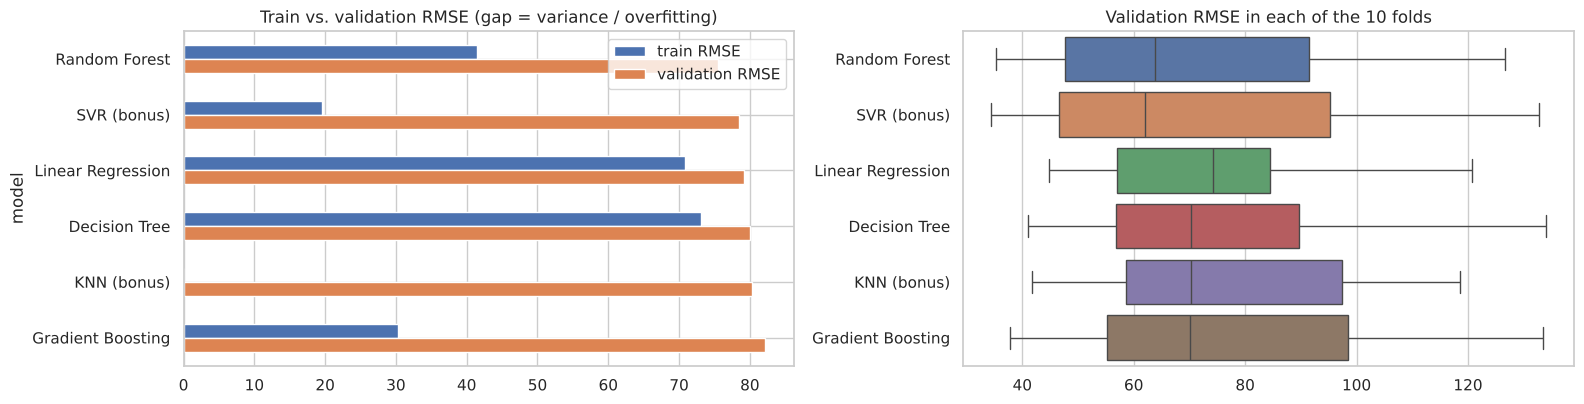

In [6]:
reg_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.5,
                                           n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31,
                                                       random_state=RANDOM_STATE),
    "KNN (bonus)": KNeighborsRegressor(n_neighbors=10, weights="distance"),
    "SVR (bonus)": TransformedTargetRegressor(regressor=SVR(kernel="rbf", C=10, epsilon=0.05),
                                              transformer=StandardScaler()),
}
hp = pd.DataFrame({"hyperparameters": {
    "Linear Regression": "ordinary least squares (default)",
    "Decision Tree": "max_depth=8, min_samples_leaf=20 (fixed to limit variance)",
    "Random Forest": "300 trees, min_samples_leaf=2, max_features=0.5",
    "Gradient Boosting": "HistGradientBoosting: 400 iterations, learning_rate=0.05, max_leaf_nodes=31",
    "KNN (bonus)": "k=10 neighbours, distance-weighted, Euclidean on standardized features",
    "SVR (bonus)": "RBF kernel, C=10, epsilon=0.05, target standardized"}})
display(hp)

reg_oof, reg_folds = {}, {}
for name, est in reg_models.items():
    reg_oof[name], reg_folds[name] = cv_regression(est, REG_NUM, kf)

y_reg = df[REG_TARGET].values
rows = []
for name, p in reg_oof.items():
    f = reg_folds[name]
    rows.append({"model": name, "MSE": mean_squared_error(y_reg, p), "RMSE": rmse(y_reg, p),
                 "MAE": mean_absolute_error(y_reg, p), "MedianAE": median_absolute_error(y_reg, p),
                 "R2": r2_score(y_reg, p), "train RMSE": f.train_RMSE.mean(),
                 "gap (val - train)": f.val_RMSE.mean() - f.train_RMSE.mean(),
                 "fold sd of RMSE": f.val_RMSE.std(), "% negative predictions": 100 * (p < 0).mean(),
                 "fit time (s)": f.seconds.sum()})
reg_results = pd.DataFrame(rows).set_index("model").sort_values("RMSE")
display(reg_results)
BEST_REG = reg_results.index[0]
print(f"Auto-summary: best by RMSE = {BEST_REG} (R2 {reg_results.R2.iloc[0]:.3f}); best by MAE = {reg_results.MAE.idxmin()}; "
      f"best by MedianAE = {reg_results.MedianAE.idxmin()}")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
plot_df = reg_results[["train RMSE", "RMSE"]].rename(columns={"RMSE": "validation RMSE"})
plot_df.plot.barh(ax=axes[0]); axes[0].set_title("Train vs. validation RMSE (gap = variance / overfitting)"); axes[0].invert_yaxis()
box = pd.DataFrame({m: reg_folds[m].val_RMSE for m in reg_results.index})
sns.boxplot(data=box, orient="h", ax=axes[1]); axes[1].set_title(f"Validation RMSE in each of the {K_FOLDS} folds")
plt.tight_layout(); plt.show()

🔎 **Relative performance — the ranking depends on the metric**
* **Random Forest is best on every metric:** RMSE 75.4 kg, MAE 30.0 kg, MedianAE 10.6 kg, $R^2$ = 0.524. Its typical error (median 10.6 kg) is small; its RMSE is 7× larger than its median error — a first sign of **heavy-tailed errors** (Section 4.5).
* **$R^2$ is only 0.43–0.52 for every model.** Even the best model leaves half of the variance unexplained: in squared-error terms, the target is dominated by a few very heavy Pokémon whose weight is not predictable from these features.
* **The metrics disagree on the rest of the ranking.** Linear Regression is 3rd by RMSE (79.2) but **last by MAE (40.7) and MedianAE (22.9)** — it is bad for typical Pokémon but, being a smooth global fit, not much worse on the extremes. The Decision Tree is the opposite: good MedianAE (10.9) but RMSE 80.1.
* **Impossible predictions:** linear regression predicts a **negative weight for 16.4%** of Pokémon (SVR 6.7%, Gradient Boosting 8.5%). Tree averages (Decision Tree, Random Forest) and KNN cannot leave the range of the training targets → 0%.
* **Bias–variance in numbers (train vs. validation RMSE):**
  * *High bias, low variance:* Linear Regression (train 70.8, gap 5.0) and the depth-limited Decision Tree (train 73.1, gap 2.0) — they fit the training data almost as badly as new data.
  * *High variance:* KNN memorizes the training set (train RMSE **0**, gap 76.4); Gradient Boosting (gap 46.9) and SVR (gap 52.3) also fit the training folds far better than new data.
  * *Best compromise:* Random Forest (train 41.5, gap 28.6) — averaging 300 trees reduces variance without the bias of a single shallow tree.
* **Gradient Boosting is last by RMSE (82.1)** although it is usually the strongest tabular model: with 702 training rows and extreme targets, boosting keeps fitting the residuals of the outliers (it is the most outlier-sensitive ensemble).
* **Stability:** the per-fold RMSE varies a lot for every model (sd 24–33 kg); the boxplot shows that the ranking can change from fold to fold — differences of a few kg between models are within noise.

# 4. Regression Error Analysis [assignment §1]
## 4.1 Residual analysis
📘 **Residual** $e_i = y_i - \hat y_i$ (positive = the model **under-predicts** the weight). For each model we check:
* **Centering:** mean and median residual; a one-sample *t*-test of $H_0$: mean = 0.
* **Systematic patterns:** the binned mean of the residual as a function of $\hat y$ (red line) should be flat at 0.
* **Heteroscedasticity** (non-constant variance): (a) the Spearman correlation between $|e|$ and $\hat y$; (b) the ratio of the residual sd in the top vs. bottom prediction decile; (c) the **Breusch–Pagan test** — regress $e^2$ on the features; under homoscedasticity $LM = nR^2 \sim \chi^2_p$.
* **Independence:** the **Durbin–Watson** statistic $DW=\sum (e_t-e_{t-1})^2/\sum e_t^2$ computed in **Pokédex order**, where members of the same evolution family are adjacent; $DW\approx 2$ = no autocorrelation, $DW<2$ = neighbours have similar errors.

,mean residual,t-test p (mean = 0),median residual,% residuals > 0,"Spearman(|e|, ŷ)",sd top / bottom decile,Breusch-Pagan LM,BP p-value,Durbin-Watson (Pokédex order)
model,,,,,,,,,
Linear Regression,-0.149,0.958,-2.303,46.863,0.425,11.124,96.932,0.000,2.114
Decision Tree,1.933,0.500,-2.368,40.205,0.695,1.709,98.354,0.000,2.087
Random Forest,0.448,0.868,-3.833,32.266,0.688,30.656,98.835,0.000,2.215
Gradient Boosting,1.393,0.636,-0.535,48.784,0.575,1.686,115.842,0.000,2.357
KNN (bonus),4.392,0.127,-4.406,38.540,0.657,30.432,113.956,0.000,2.102
SVR (bonus),1.344,0.633,-2.945,42.894,0.601,12.247,128.227,0.000,2.233


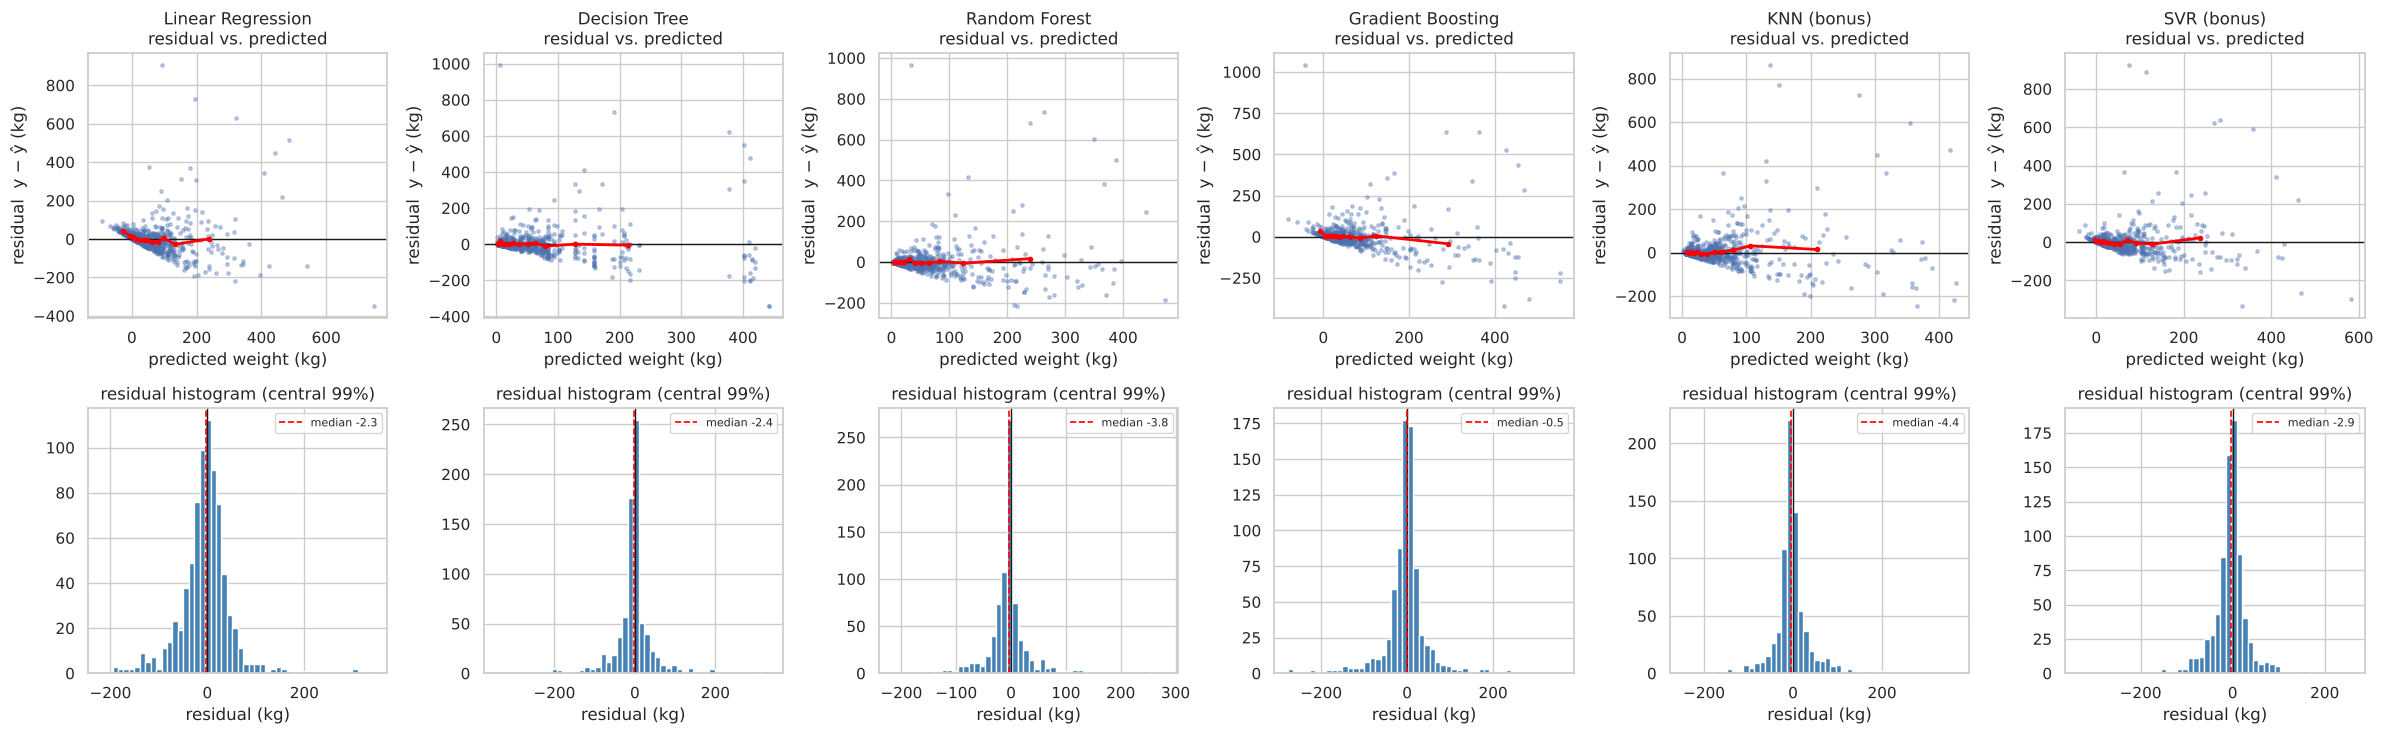

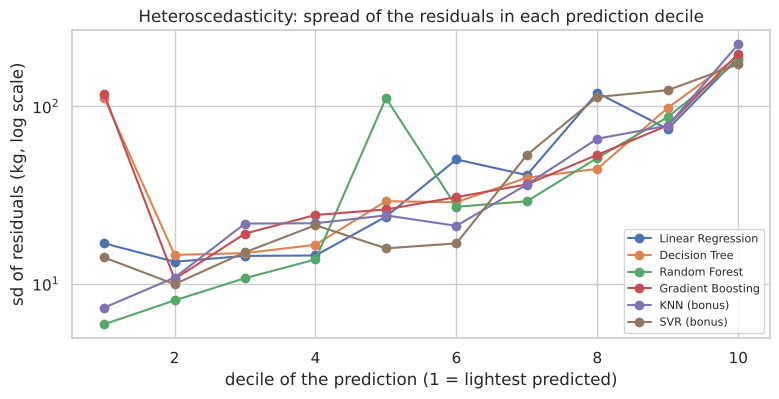

In [7]:
def breusch_pagan(resid, X_design):
    """LM test: regress e^2 on the features; LM = n * R^2 ~ chi2(p) under homoscedasticity."""
    Xd = np.column_stack([np.ones(len(resid)), X_design])
    e2 = resid ** 2
    beta, *_ = np.linalg.lstsq(Xd, e2, rcond=None)
    r2 = 1 - ((e2 - Xd @ beta) ** 2).sum() / ((e2 - e2.mean()) ** 2).sum()
    lm = len(resid) * r2
    return lm, stats.chi2.sf(lm, Xd.shape[1] - 1)

X_bp = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(df[REG_NUM]))
order = df.pokedex_number.argsort().values          # Pokédex order (evolution families are adjacent)
res = {m: y_reg - p for m, p in reg_oof.items()}

rows = []
for m, r in res.items():
    p = reg_oof[m]
    dec = pd.qcut(p, 10, labels=False, duplicates="drop")
    sd_dec = pd.Series(r).groupby(dec).std()
    lm, p_bp = breusch_pagan(r, X_bp)
    ro = r[order]
    rows.append({"model": m, "mean residual": r.mean(), "t-test p (mean = 0)": stats.ttest_1samp(r, 0).pvalue,
                 "median residual": np.median(r), "% residuals > 0": 100 * (r > 0).mean(),
                 "Spearman(|e|, ŷ)": stats.spearmanr(np.abs(r), p)[0],
                 "sd top / bottom decile": sd_dec.iloc[-1] / sd_dec.iloc[0],
                 "Breusch-Pagan LM": lm, "BP p-value": p_bp,
                 "Durbin-Watson (Pokédex order)": (np.diff(ro) ** 2).sum() / (ro ** 2).sum()})
resid_table = pd.DataFrame(rows).set_index("model")
display(resid_table)

def binned_mean(ax, x, y, bins=12, color="red", stat="mean"):
    x, y = pd.Series(np.asarray(x, float)), pd.Series(np.asarray(y, float))
    ok = x.notna(); x, y = x[ok], y[ok]
    if x.nunique() <= 10:
        g = y.groupby(x); ax.plot(g.agg(stat).index, g.agg(stat).values, "o-", color=color, lw=2, ms=3)
    else:
        b = pd.qcut(x, bins, duplicates="drop")
        ax.plot(x.groupby(b, observed=True).median(), y.groupby(b, observed=True).agg(stat), "o-", color=color, lw=2, ms=3)

models = list(reg_oof)
fig, axes = plt.subplots(2, len(models), figsize=(4 * len(models), 7.5))
for j, m in enumerate(models):
    r, p = res[m], reg_oof[m]
    ax = axes[0, j]; ax.scatter(p, r, s=6, alpha=.35); ax.axhline(0, color="k", lw=1); binned_mean(ax, p, r)
    ax.set(title=f"{m}\nresidual vs. predicted", xlabel="predicted weight (kg)", ylabel="residual  y − ŷ (kg)")
    lim = np.quantile(np.abs(r), .99); ax = axes[1, j]
    ax.hist(r[np.abs(r) <= lim], bins=50, color="steelblue"); ax.axvline(0, color="k", lw=1)
    ax.axvline(np.median(r), color="red", ls="--", lw=1.2, label=f"median {np.median(r):.1f}")
    ax.set(title="residual histogram (central 99%)", xlabel="residual (kg)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
for m in models:
    dec = pd.qcut(reg_oof[m], 10, labels=False, duplicates="drop")
    sd = pd.Series(res[m]).groupby(dec).std(); ax.plot(sd.index + 1, sd.values, "o-", label=m)
ax.set(yscale="log", xlabel="decile of the prediction (1 = lightest predicted)", ylabel="sd of residuals (kg, log scale)",
       title="Heteroscedasticity: spread of the residuals in each prediction decile"); ax.legend(fontsize=8)
plt.show()

🔎 **Are the residuals centred? Patterns? Heteroscedasticity?**
* **Centred in the mean, not in the median.** Mean residuals are between −0.15 and +4.4 kg and no *t*-test rejects mean = 0 (all *p* ≥ 0.13). But the **median residual is negative for every model** (−0.5 to −4.4 kg) and only **32% of Random Forest's residuals are positive**: the model slightly *over*-predicts most Pokémon and compensates with a few very large *under*-predictions. The mean hides an asymmetric distribution (quantified in 4.5).
* **Systematic pattern in the linear model:** in the residual-vs-predicted plot, the points at the left form a straight diagonal band — wherever linear regression predicts a low or negative weight the residual is forced to be positive (true weights are ≥ 0.1 kg). This is a **formulation/model problem**: a linear model on an unbounded scale for a positive, multiplicative quantity. For the tree-based models the binned mean stays close to 0.
* **Strong heteroscedasticity for every model.** The residual spread grows with the prediction ("funnel" shape): Spearman$(|e|,\hat y)$ = 0.43 (linear) to 0.70 (tree); for Random Forest the residual sd in the heaviest-predicted decile is **31×** that of the lightest decile (linear: 11×). The **Breusch–Pagan test rejects homoscedasticity for all six models** (LM 97–128, *p* < 0.001). The heteroscedasticity plot (log scale) shows the residual sd climbing from a few kg to > 100 kg. For the Decision Tree and Gradient Boosting the decile ratio is small (≈ 1.7) only because their lowest decile already contains some large errors — the test and the plot still show the effect.
* **Independence:** Durbin–Watson in Pokédex order is 2.09–2.36 for all models, i.e. **no positive autocorrelation**: although evolution families are adjacent and share a body plan, the models do not leave a family-level error pattern. The independence assumption is acceptable.
* **Why heteroscedasticity is expected here:** weight is multiplicative (a 10% error on a 500 kg Pokémon is 50 kg; on a 5 kg Pokémon it is 0.5 kg). Constant-variance errors exist on the **log scale**, not on the kg scale — this motivates the experiment in 4.6.

## 4.2 Is there a sector with higher error rates? — error by primary type
We compare the absolute error (MAE, median AE), the **relative MAE** (MAE / mean weight of the type — heavier types naturally have larger errors in kg), the bias (mean residual) and each type's share of the top-5% largest errors vs. its share of the data. Right panel: a crude **"body density" proxy** $w/h^3$ (kg/m³) — information that is *not* among the features.

,model,n,mean_weight,MAE,median_AE,mean_residual,n_top5,relative MAE %,share of top-5% errors %,share of data %
type1,,,,,,,,,,
steel,Random Forest,24,188.842,100.930,40.448,62.149,6,53.447,15.000,3.073
ground,Random Forest,27,150.044,80.880,27.253,50.129,3,53.904,7.500,3.457
ghost,Random Forest,27,69.570,47.940,18.273,1.225,2,68.909,5.000,3.457
psychic,Random Forest,52,57.329,45.332,14.435,-2.280,4,79.073,10.000,6.658
dragon,Random Forest,27,107.126,43.883,22.968,-23.774,3,40.964,7.500,3.457
ice,Random Forest,23,103.261,43.806,14.235,30.268,2,42.422,5.000,2.945
rock,Random Forest,41,92.946,41.050,25.747,9.719,4,44.166,10.000,5.250
dark,Random Forest,29,69.097,32.952,9.451,8.022,1,47.689,2.500,3.713
fire,Random Forest,50,66.096,27.194,9.326,9.407,4,41.143,10.000,6.402


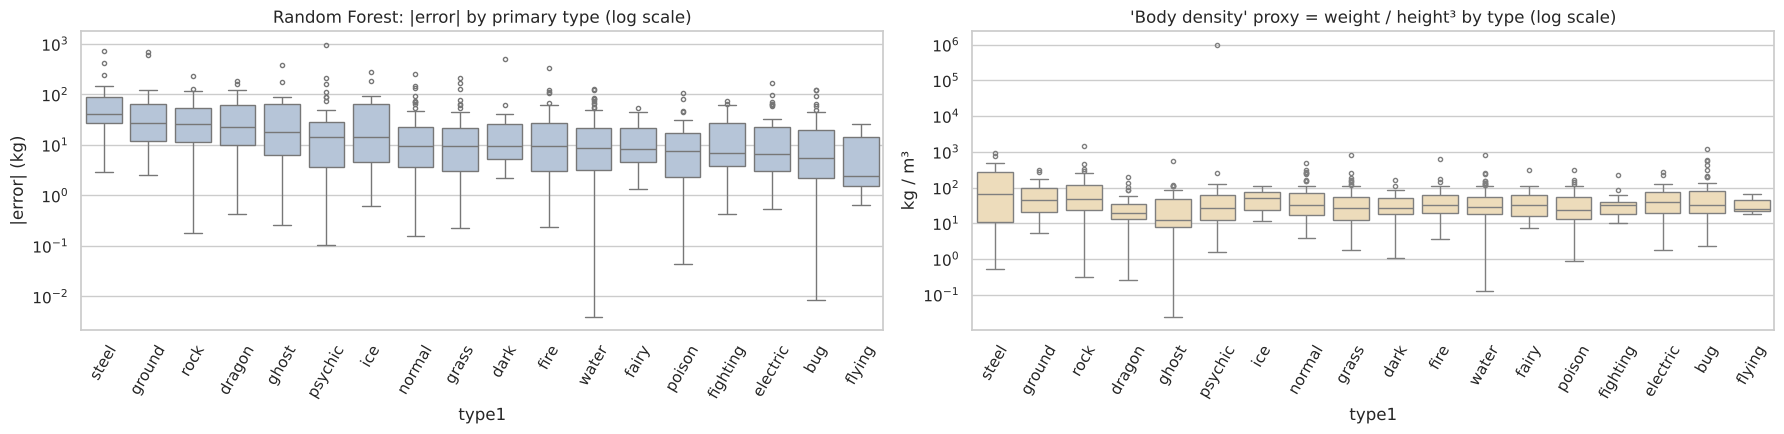

Within-type spread of the density proxy (types with the largest spread):


type1,steel,dragon,ghost,poison,rock,bug
median density,66.870,19.092,12.000,23.016,46.815,33.167
p90 / p10 spread,116.716,56.931,33.779,28.613,21.266,17.119


In [8]:
sector_rows = []
for m in [BEST_REG, "Linear Regression"]:
    r = res[m]
    t = pd.DataFrame({GROUP_COL: df[GROUP_COL], "abs_err": np.abs(r), "res": r, "y": y_reg,
                      "top5": np.abs(r) >= np.quantile(np.abs(r), .95)})
    g = t.groupby(GROUP_COL).agg(n=("y", "size"), mean_weight=("y", "mean"), MAE=("abs_err", "mean"),
                                 median_AE=("abs_err", "median"), mean_residual=("res", "mean"), n_top5=("top5", "sum"))
    g["relative MAE %"] = 100 * g.MAE / g.mean_weight
    g["share of top-5% errors %"] = 100 * g.n_top5 / t.top5.sum()
    g["share of data %"] = 100 * g.n / len(t)
    g.insert(0, "model", m); sector_rows.append(g)
sector = pd.concat(sector_rows)
display(sector[sector.model == BEST_REG].sort_values("MAE", ascending=False))

t = pd.DataFrame({GROUP_COL: df[GROUP_COL], "abs_err": np.abs(res[BEST_REG]),
                  "density": df.weight_kg / df.height_m ** 3})
order_types = t.groupby(GROUP_COL).abs_err.median().sort_values(ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(18, 4.5))
sns.boxplot(data=t, x=GROUP_COL, y="abs_err", order=order_types, ax=axes[0], color="lightsteelblue", fliersize=3)
axes[0].set(yscale="log", title=f"{BEST_REG}: |error| by primary type (log scale)", ylabel="|error| (kg)")
axes[0].tick_params(axis="x", rotation=60)
sns.boxplot(data=t, x=GROUP_COL, y="density", order=order_types, ax=axes[1], color="wheat", fliersize=3)
axes[1].set(yscale="log", title="'Body density' proxy = weight / height³ by type (log scale)", ylabel="kg / m³")
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()
dens = t.groupby(GROUP_COL).density.agg(["median", lambda s: s.quantile(.9) / s.quantile(.1)])
dens.columns = ["median density", "p90 / p10 spread"]
print("Within-type spread of the density proxy (types with the largest spread):")
display(dens.sort_values("p90 / p10 spread", ascending=False).head(6).T)

🔎 **Steel and Ground are the problem sectors — because of density, which the model cannot see**
* **Steel** is the worst type: MAE **100.9 kg** (vs. 30.0 overall), mean residual **+62 kg** (systematically under-predicted), and it holds **15% of the top-5% errors while being 3.1% of the data** (5× over-represented). **Ground** follows: MAE 80.9 kg, mean residual +50 kg.
* **Relative error tells a second story:** Psychic (79%), Fairy (72%) and Ghost (69%) have the largest *relative* MAE. Fairy is systematically **over**-predicted (mean residual −16.9 kg: light, delicate Pokémon); Psychic contains Cosmoem (0.1 m, 999.9 kg) and Cosmog (0.1 kg).
* **Why?** Weight = density × volume. The features describe size (height) and fighting ability, **not what the Pokémon is made of**. The density proxy shows it: Steel has the highest median density (67 kg/m³) and by far the **largest within-type spread — the 90th percentile is 117× the 10th** (iron giants like Metagross vs. light floating ones), followed by Dragon (57×) and Ghost (34×). A type with a wide spread of densities cannot be modelled with height + type alone. This is a **data limitation (missing feature)**, not a modelling failure.
* **Best-predicted types:** Water and Fighting (MAE ≈ 17.7 kg, relative 30–35%) — body plans close to "normal animals/humans" where height predicts weight well. (Flying has only 3 Pokémon — its numbers are not reliable.)

## 4.3 Error as a function of the features
Each panel shows a feature vs. the residual (or the absolute error) with the binned mean in red. A flat red line at 0 = no feature-dependent bias; a rising line in the |error| plots = the error grows with that feature. The table gives the Spearman correlation of each feature with the residual and with |error|. The last figure looks for **hidden sub-populations** in the (log height, log weight) plane.

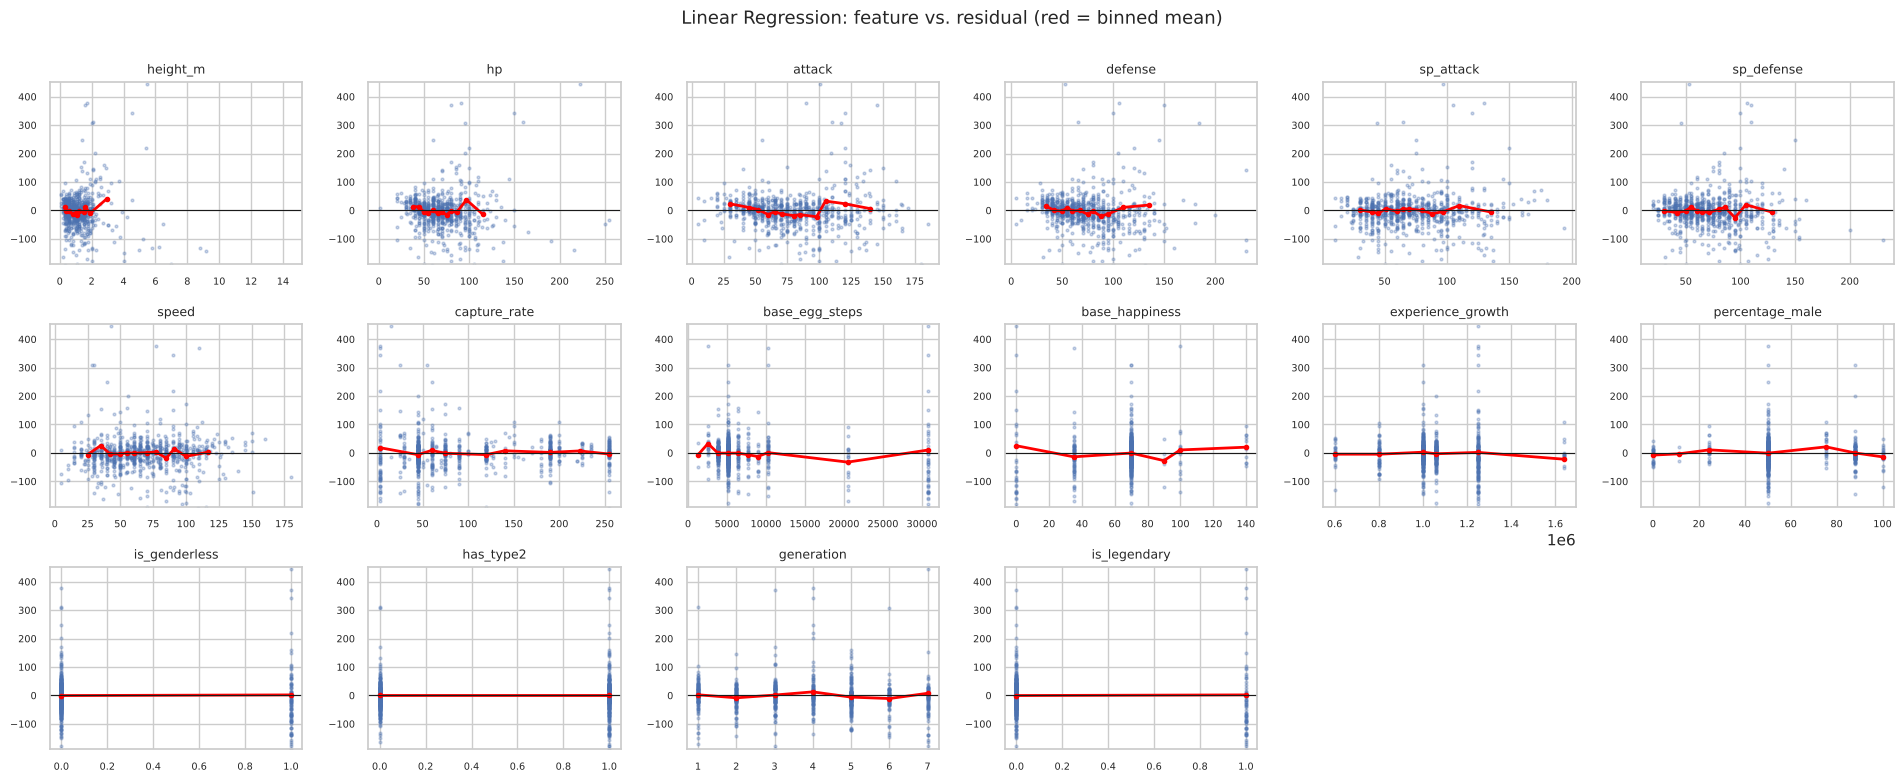

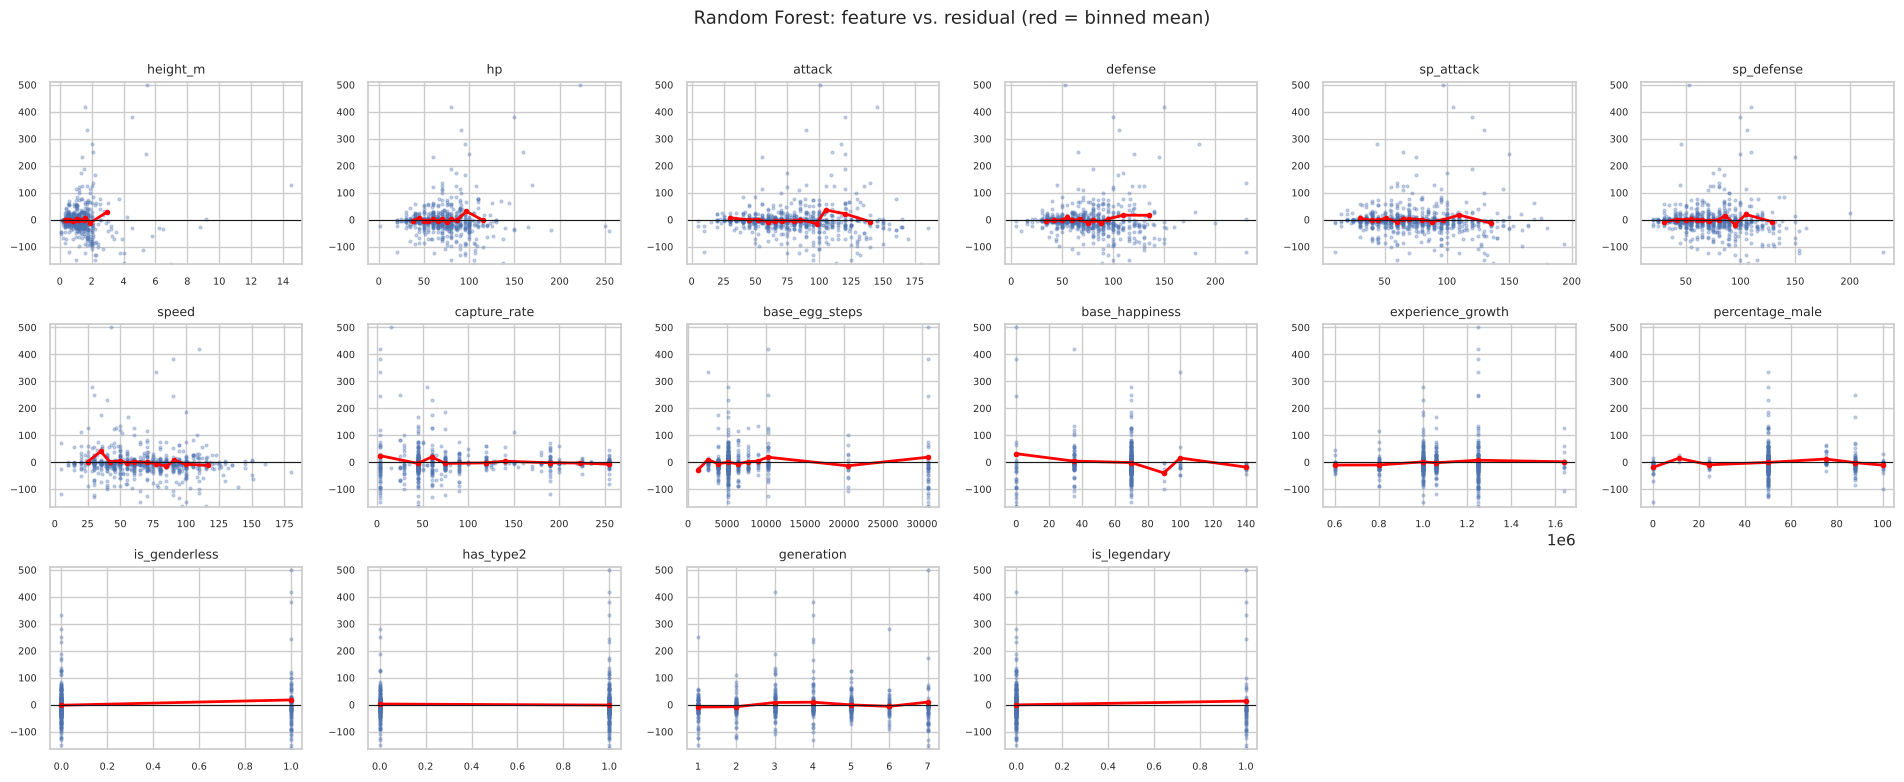

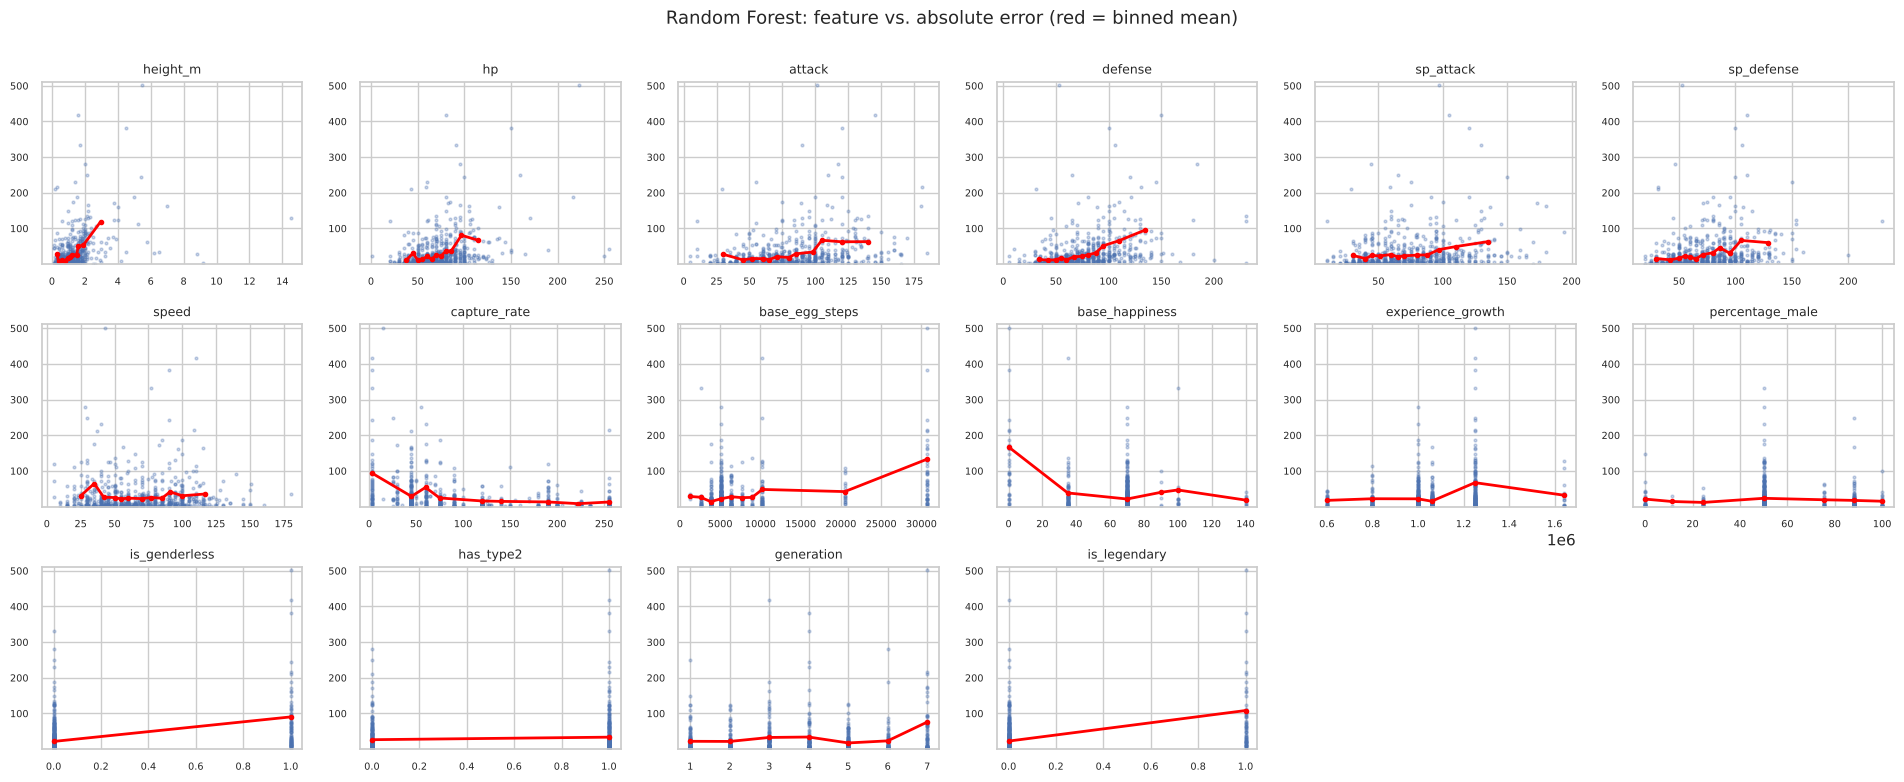

,Linear Regression: ρ with residual,Linear Regression: ρ with |error|,Random Forest: ρ with residual,Random Forest: ρ with |error|
height_m,-0.067,0.278,-0.125,0.526
defense,-0.250,0.243,-0.168,0.504
hp,-0.176,0.216,-0.135,0.446
sp_defense,-0.131,0.238,-0.177,0.402
attack,-0.150,0.188,-0.132,0.395
is_genderless,-0.120,0.312,-0.060,0.329
base_egg_steps,-0.109,0.267,-0.089,0.316
sp_attack,-0.030,0.101,-0.154,0.304
is_legendary,-0.142,0.306,-0.178,0.300
experience_growth,-0.075,0.125,-0.008,0.178


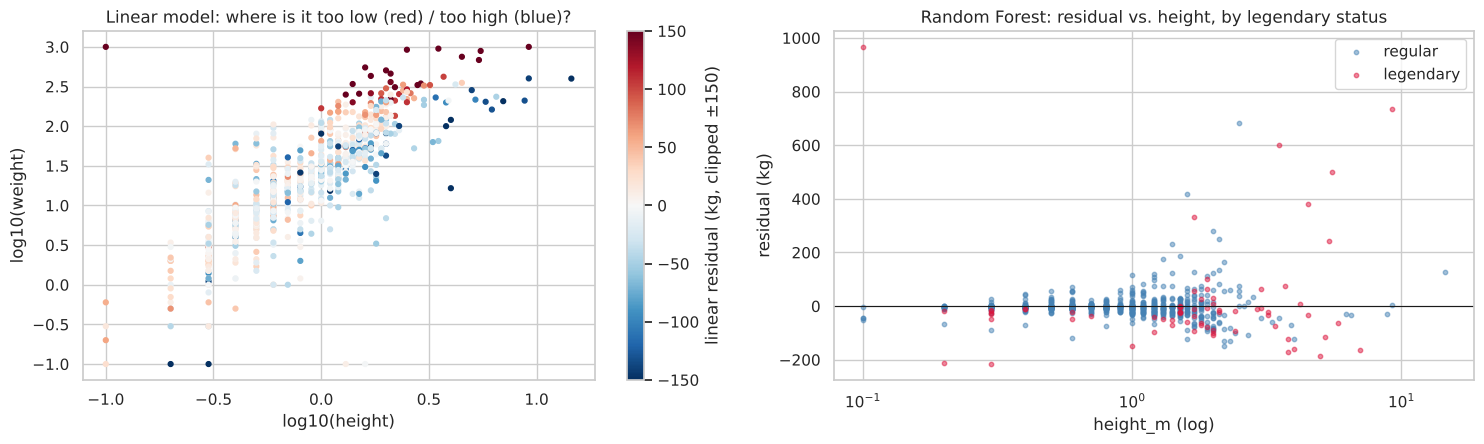

MAE of Random Forest: legendary 108.2 kg vs. regular 22.4 kg


In [9]:
def feature_grid(model, kind):
    r = res[model]; yv = r if kind == "residual" else np.abs(r)
    feats = [c for c in REG_NUM if c != "is_legendary"] + ["is_legendary"]
    ncol = 6; nrow = int(np.ceil(len(feats) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 2.6 * nrow))
    for ax, f in zip(axes.ravel(), feats):
        ax.scatter(df[f], yv, s=4, alpha=.3); binned_mean(ax, df[f], yv)
        if kind == "residual": ax.axhline(0, color="k", lw=.8)
        ax.set_title(f, fontsize=9); ax.tick_params(labelsize=7)
        ax.set_ylim(np.quantile(yv, .005), np.quantile(yv, .995))
    for ax in axes.ravel()[len(feats):]: ax.axis("off")
    fig.suptitle(f"{model}: feature vs. {kind} (red = binned mean)", y=1.0, fontsize=13)
    plt.tight_layout(); plt.show()

for m in ["Linear Regression", BEST_REG]:
    feature_grid(m, "residual")
feature_grid(BEST_REG, "absolute error")

corr = pd.DataFrame({
    (m, what): {f: stats.spearmanr(df[f], (res[m] if what == "residual" else np.abs(res[m])), nan_policy="omit")[0]
                for f in REG_NUM}
    for m in ["Linear Regression", BEST_REG] for what in ["residual", "|error|"]})
corr.columns = [f"{m}: ρ with {w}" for m, w in corr.columns]
display(corr.sort_values(f"{BEST_REG}: ρ with |error|", ascending=False))

# hidden sub-populations: residual of the linear model in the (log height, log weight) plane
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
sc = axes[0].scatter(np.log10(df.height_m), np.log10(df.weight_kg), c=np.clip(res["Linear Regression"], -150, 150),
                     cmap="RdBu_r", s=12)
plt.colorbar(sc, ax=axes[0], label="linear residual (kg, clipped ±150)")
axes[0].set(title="Linear model: where is it too low (red) / too high (blue)?", xlabel="log10(height)", ylabel="log10(weight)")
for grp, col in [(0, "steelblue"), (1, "crimson")]:
    m_ = df.is_legendary == grp
    axes[1].scatter(df.height_m[m_], res[BEST_REG][m_], s=10, alpha=.5, c=col, label=["regular", "legendary"][grp])
axes[1].axhline(0, color="k", lw=.8); axes[1].set_xscale("log"); axes[1].legend()
axes[1].set(title=f"{BEST_REG}: residual vs. height, by legendary status", xlabel="height_m (log)", ylabel="residual (kg)")
plt.tight_layout(); plt.show()
print(f"MAE of {BEST_REG}: legendary {np.abs(res[BEST_REG][df.is_legendary == 1]).mean():.1f} kg vs. "
      f"regular {np.abs(res[BEST_REG][df.is_legendary == 0]).mean():.1f} kg")

🔎 **Non-linearity, feature-dependent errors, hidden sub-populations**
* **Little bias, a lot of feature-dependent spread.** Correlations of the features with the *signed* residual are weak (|ρ| ≤ 0.25): no single feature causes a large systematic over- or under-prediction once the model is fitted. Correlations with the *absolute* error are much stronger for Random Forest: **height ρ = 0.53, defense 0.50, hp 0.45**, attack/sp_defense 0.40, and **capture_rate −0.40** (hard-to-catch Pokémon, i.e. legendaries, have larger errors). The error grows with size and with "power".
* **Non-linear relationship missed by the linear model.** In the (log height, log weight) map, the linear model's errors are not random: it **under-predicts** (red) the heavy, compact Pokémon in the upper part of the cloud and **over-predicts** (blue) tall but light ones (snakes and dragons such as Rayquaza or Steelix). A straight line in *kg vs. m* cannot follow a power law $w \propto h^{1.77}$ with type-dependent density.
* **Hidden sub-population: legendaries.** The right panel shows that many of the large residuals at heights above ≈ 2 m belong to **legendary** Pokémon (red). Random Forest's MAE is **108.2 kg on legendaries vs. 22.4 kg on regular Pokémon** (4.8×). Legendaries are designed as "extraordinary" (giant, cosmic, or paper-thin) and do not follow the body-plan rules of regular Pokémon; with 69 of them spread over 18 types, the model cannot learn their rules.
* **Discrete features** (`base_egg_steps`, `experience_growth`, `base_happiness`) show vertical stripes: they encode game-design categories, and their extreme categories (30,720 egg steps, happiness 0) coincide with legendaries — they matter through the sub-population, not as physical causes.

## 4.4 Analysis of extreme errors — the top 5%
The 5% of Pokémon with the largest absolute error of the best model are listed below, each with an automatic, rule-based **diagnosis** (several reasons can apply):
* **DATA** — the value sits at the 999.9 kg ceiling, or a feature is missing;
* **RARE** — weight above the 99th percentile, an unusually dense/light body (density proxy outside its 5–95% range), or the legendary sub-population;
* **MODEL** — the true weight is above anything the model ever predicts (tree ensembles cannot extrapolate), or the features are ordinary and the weight is simply unexpected for them.

In [10]:
r = res[BEST_REG]; abs_r = np.abs(r)
thr = np.quantile(abs_r, .95); top = abs_r >= thr
density = df.weight_kg / df.height_m ** 3
d_lo, d_hi = density.quantile([.05, .95])
miss_cols = [c for c in REG_NUM if c != "percentage_male"]          # percentage_male is NaN by design

def diagnose(i):
    reasons = []
    if df.weight_kg[i] == 999.9: reasons.append("DATA: value at the 999.9 kg cap (censored?)")
    if df.loc[i, miss_cols].isna().any(): reasons.append("DATA: missing feature")
    if df.weight_kg[i] > df.weight_kg.quantile(.99): reasons.append("RARE: weight > p99")
    if density[i] > d_hi: reasons.append("RARE: unusually dense body")
    if density[i] < d_lo: reasons.append("RARE: unusually light body")
    if df.is_legendary[i] == 1: reasons.append("RARE: legendary sub-population")
    if r[i] > 0 and reg_oof[BEST_REG][i] < np.quantile(reg_oof[BEST_REG], .99) and df.weight_kg[i] > reg_oof[BEST_REG].max():
        reasons.append("MODEL: target above the largest prediction (trees cannot extrapolate)")
    if not reasons: reasons.append("MODEL: ordinary features, unexpected weight")
    return "; ".join(reasons)

ext = df.loc[top, ID_COLS + [GROUP_COL, "height_m", REG_TARGET]].copy()
ext["predicted"] = reg_oof[BEST_REG][top]; ext["residual"] = r[top]
ext["density (kg/m³)"] = density[top]; ext["legendary"] = df.is_legendary[top]
ext["diagnosis"] = [diagnose(i) for i in ext.index]
ext = ext.reindex(ext.residual.abs().sort_values(ascending=False).index)
print(f"Top 5% absolute errors of {BEST_REG}: |error| ≥ {thr:.1f} kg -> {top.sum()} Pokémon "
      f"({100 * (r[top] > 0).mean():.0f}% under-predicted)")
display(ext.head(20))

cats = pd.Series({k: ext.diagnosis.str.contains(k).mean() * 100 for k in ["DATA", "RARE", "MODEL"]}, name="% of extreme rows")
display(cats.to_frame().T)
cmp = pd.DataFrame({"top 5% (mean)": df.loc[top, REG_NUM].mean(), "rest (mean)": df.loc[~top, REG_NUM].mean()})
cmp["ratio"] = cmp.iloc[:, 0] / cmp.iloc[:, 1]
display(cmp.sort_values("ratio", ascending=False).head(8).T)
print("Types among the extreme rows:", df.loc[top, GROUP_COL].value_counts().head(6).to_dict())

Top 5% absolute errors of Random Forest: |error| ≥ 108.8 kg -> 40 Pokémon (60% under-predicted)


,name,classfication,type1,height_m,weight_kg,predicted,residual,density (kg/m³),legendary,diagnosis
769,Cosmoem,Protostar Pokémon,psychic,0.100,999.900,33.087,966.813,"999,900.000",1,DATA: value at the 999.9 kg cap (censored?); R...
776,Celesteela,Launch Pokémon,steel,9.200,999.900,263.656,736.244,1.284,1,DATA: value at the 999.9 kg cap (censored?); R...
729,Mudsdale,Draft Horse Pokémon,ground,2.500,920.000,238.933,681.067,58.880,0,RARE: weight > p99; MODEL: target above the la...
364,Groudon,Continent Pokémon,ground,3.500,950.000,349.482,600.518,22.157,1,RARE: weight > p99; RARE: legendary sub-popula...
778,Guzzlord,Junkivore Pokémon,dark,5.500,888.000,387.071,500.929,5.337,1,RARE: weight > p99; RARE: legendary sub-popula...
357,Metagross,Iron Leg Pokémon,steel,1.600,550.000,132.136,417.864,134.277,0,RARE: weight > p99; MODEL: target above the la...
468,Giratina,Renegade Pokémon,ghost,4.500,750.000,367.506,382.494,8.230,1,RARE: weight > p99; RARE: legendary sub-popula...
466,Heatran,Lava Dome Pokémon,fire,1.700,430.000,97.450,332.550,87.523,1,RARE: legendary sub-population
694,Avalugg,Iceberg Pokémon,ice,2.000,505.000,224.817,280.183,63.125,0,MODEL: target above the largest prediction (tr...
124,Snorlax,Sleeping Pokémon,normal,2.100,460.000,210.545,249.455,49.671,0,"MODEL: ordinary features, unexpected weight"


,DATA,RARE,MODEL
% of extreme rows,5.000,52.500,60.000


,is_legendary,is_genderless,height_m,base_egg_steps,defense,hp,attack,sp_defense
top 5% (mean),0.425,0.500,2.917,"16,576.000",110.950,96.075,103.525,93.425
rest (mean),0.070,0.104,1.069,"6,719.568",70.954,67.695,76.300,69.808
ratio,6.056,4.812,2.729,2.467,1.564,1.419,1.357,1.338


Types among the extreme rows: {'steel': 6, 'fire': 4, 'rock': 4, 'psychic': 4, 'normal': 3, 'dragon': 3}


🔎 **Individual analysis — data quality, model limitations or rare cases?**
The 40 Pokémon with |error| ≥ 108.8 kg are **60% under-predicted**, **6× more often legendary** than the rest (42.5% vs. 7.0%), **2.7× taller** and 1.6× higher in defense. Steel (6), Fire, Rock and Psychic (4 each) are the most frequent types.

| Pokémon | true → predicted (kg) | Why | Category |
|---|---|---|---|
| **Cosmoem** | 999.9 → 33 | 0.1 m tall and 999.9 kg — a "proto-star". Physically absurd ($10^6$ kg/m³) and stored at the game's maximum weight. | **Data** (ceiling) + **rare** |
| **Celesteela** | 999.9 → 264 | a 9.2 m steel rocket, again exactly 999.9 kg | **Data** (ceiling) + **rare** |
| **Mudsdale** | 920 → 239 | a *regular* draft-horse Pokémon; nothing in its stats announces 920 kg | **Model / missing feature** (density) |
| **Groudon, Guzzlord, Giratina** | 950 / 888 / 750 → 349–387 | giant legendaries | **Rare** + **model** (forests average leaves → cannot reach the extremes) |
| **Metagross** | 550 → 132 | a 1.6 m "iron" Pokémon: density 134 kg/m³ | **Rare** (density) |
| **Kartana** | 0.1 → 216 | a legendary that is a sheet of paper; stats (attack 181) look like a heavy legendary | **Rare** — the model generalizes from other legendaries |
| **Cosmog** | 0.1 → 211 | a legendary "gas cloud"; "legendary + genderless" pushes the prediction up | **Rare** |
| **Rayquaza, Zygarde, Xurkitree** | 206 / 285 / 100 → 370 / 472 / 272 | very tall but light (serpents, wires) | **Rare** (light body) |
| **Snorlax, Probopass, Glalie** | 460 / 340 / 257 → 211 / 109 / 69 | regular Pokémon, ordinary stats, very heavy for their size | **Model / missing feature** |

**Overall:** 5% of the extreme rows are pure data artifacts (the 999.9 kg ceiling), 52.5% are rare cases (mostly legendaries with non-physical bodies), and 60% show a model limitation (several reasons can apply to one row). The dominant root cause is a **missing variable — density/material** — combined with a rare, inconsistent sub-population. These Pokémon are **not errors to be removed**: they are correct game data that the chosen features cannot explain.

## 4.5 Statistical properties of the errors
📘 **MAE** $=\frac1n\sum|e_i|$; **sd of residuals**; **skewness** $=\mathbb E[(e-\bar e)^3]/\sigma^3$ (0 = symmetric; > 0 = long right tail = large under-predictions); **excess kurtosis** $=\mathbb E[(e-\bar e)^4]/\sigma^4-3$ (0 = Gaussian tails; ≫ 0 = heavy tails, a few huge errors). The **Jarque–Bera** test combines both to test normality. The ratio p95(|e|)/median(|e|) and the share of the total squared error caused by the largest errors show how concentrated the loss is.

,MAE,mean residual,sd of residuals,skewness,excess kurtosis,Jarque-Bera p,|e| p95 / median
model,,,,,,,
Linear Regression,40.718,-0.149,79.245,4.416,40.614,0.000,5.837
Decision Tree,33.888,1.933,80.098,4.976,49.377,0.000,12.022
Random Forest,30.012,0.448,75.479,6.397,63.069,0.000,10.254
Gradient Boosting,36.740,1.393,82.186,4.228,47.281,0.000,9.304
KNN (bonus),35.329,4.392,80.271,5.106,42.747,0.000,8.917
SVR (bonus),32.853,1.344,78.550,6.069,60.274,0.000,6.621


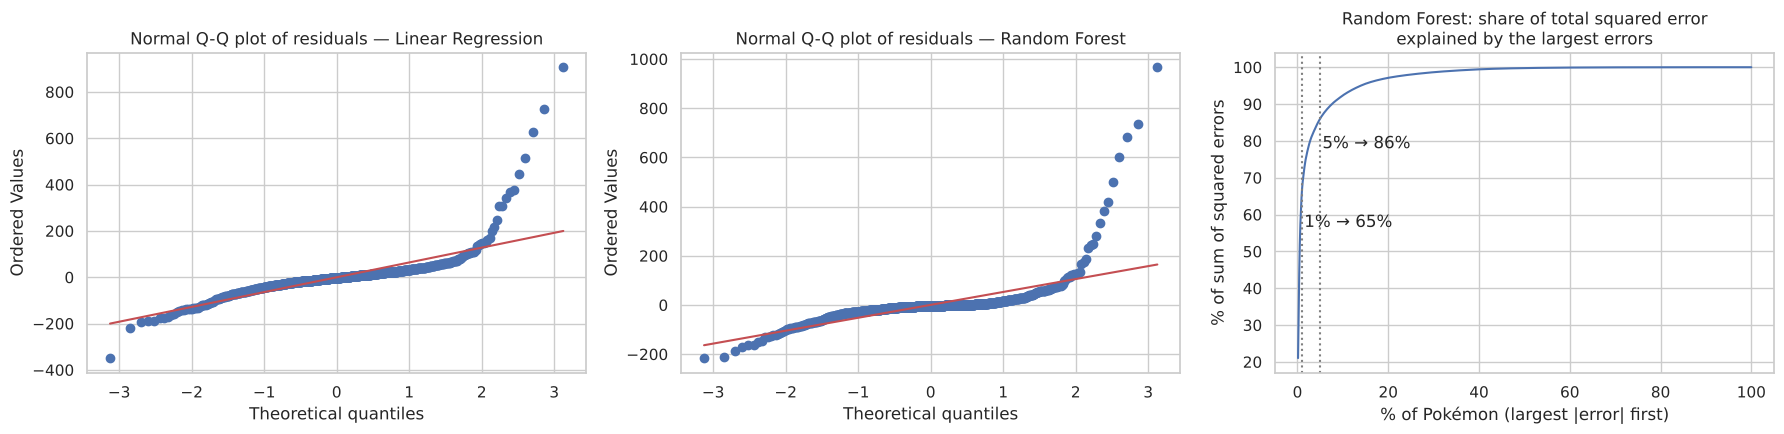

In [11]:
rows = []
for m, r in res.items():
    rows.append({"model": m, "MAE": np.abs(r).mean(), "mean residual": r.mean(), "sd of residuals": r.std(ddof=1),
                 "skewness": stats.skew(r), "excess kurtosis": stats.kurtosis(r),
                 "Jarque-Bera p": stats.jarque_bera(r).pvalue,
                 "|e| p95 / median": np.quantile(np.abs(r), .95) / np.median(np.abs(r))})
err_stats = pd.DataFrame(rows).set_index("model")
display(err_stats)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, m in zip(axes[:2], ["Linear Regression", BEST_REG]):
    stats.probplot(res[m], dist="norm", plot=ax); ax.set_title(f"Normal Q-Q plot of residuals — {m}")
r = np.sort(np.abs(res[BEST_REG]))[::-1]
axes[2].plot(np.arange(1, len(r) + 1) / len(r) * 100, np.cumsum(r ** 2) / (r ** 2).sum() * 100)
axes[2].set(title=f"{BEST_REG}: share of total squared error\nexplained by the largest errors",
            xlabel="% of Pokémon (largest |error| first)", ylabel="% of sum of squared errors")
for q in [1, 5]:
    v = np.cumsum(r ** 2)[int(len(r) * q / 100) - 1] / (r ** 2).sum() * 100
    axes[2].axvline(q, ls=":", color="gray"); axes[2].text(q + .5, v - 8, f"{q}% → {v:.0f}%")
plt.tight_layout(); plt.show()

🔎 **Heavy tails and a positive skew — instability and systematic under-prediction of the heaviest Pokémon**
* **Excess kurtosis is 41–63 for all models** (Gaussian: 0); **Jarque–Bera rejects normality** for all (*p* < 0.001). The Q-Q plots follow the line in the centre and break away sharply in the upper tail.
* **Concentration of the loss:** for Random Forest, **1% of the Pokémon produce 65% of the total squared error, and 5% produce 86%**. RMSE and $R^2$ are therefore mostly a measure of how well a model handles ~8–40 Pokémon. This is the **instability** that heavy tails indicate: removing or adding one extreme Pokémon would change the RMSE dramatically.
* **Positive skewness (4.2–6.4)** = the large errors are **under-predictions**: the models never predict the heaviest weights (systematic bias at the top). Together with the negative median residual (4.1), the error distribution is "many small over-predictions, a few huge under-predictions".
* **A trade-off between models:** Random Forest has the **lowest MAE (30.0) but the highest kurtosis (63) and skewness (6.4)**; linear regression has the highest MAE (40.7) but the lowest kurtosis (41) and the lowest p95/median ratio (5.8 vs. 10.3). The forest is very accurate for typical Pokémon and fails hard on the rare ones; the linear model is uniformly mediocre.
* **The sd of the residuals (75–82 kg) is 1.9–2.5× the MAE** (Random Forest: 2.5×) — under normality this ratio would be ≈ 1.25. The sd is not a good summary of a "typical" error here.

## 4.6 Improvement experiment — fixing the formulation (log–log model)
**Idea.** Weight is multiplicative and follows a power law of height ($w \approx c\,h^{b}$). Then $\log w = \log c + b\log h$ is **linear**, and errors on the log scale are closer to homoscedastic. We train on $\log(w)$ with the extra feature $\log(h)$, transform predictions back with $\exp$, and evaluate in kilograms as before (same folds).

In [12]:
df["log_height_m"] = np.log(df.height_m)
LOGLOG_NUM = REG_NUM + ["log_height_m"]
rows, improved = [], {}
for m in ["Linear Regression", BEST_REG]:
    est = TransformedTargetRegressor(regressor=clone(reg_models[m]), func=np.log, inverse_func=np.exp)
    improved[m], _ = cv_regression(est, LOGLOG_NUM, kf)
    for label, p in [("original", reg_oof[m]), ("log-log", improved[m])]:
        e = y_reg - p; w = np.argmax(np.abs(e))
        rows.append({"model": m, "formulation": label, "MAE": np.abs(e).mean(), "MedianAE": np.median(np.abs(e)),
                     "RMSE": rmse(y_reg, p), "R2": r2_score(y_reg, p), "% negative": 100 * (p < 0).mean(),
                     "skewness": stats.skew(e), "worst case": f"{df.name[w]} (y={y_reg[w]:.0f}, ŷ={p[w]:.0f})"})
display(pd.DataFrame(rows).set_index(["model", "formulation"]))

e_lin, e_ll = np.abs(y_reg - reg_oof["Linear Regression"]), np.abs(y_reg - improved["Linear Regression"])
print(f"Linear model: log-log is better for {100 * (e_ll < e_lin).mean():.0f}% of the Pokémon; "
      f"the 5 largest log-log errors:")
w5 = np.argsort(e_ll)[::-1][:5]
display(df.loc[w5, ["name", "type1", "height_m", "weight_kg"]].assign(predicted=improved["Linear Regression"][w5]))

MAE  MedianAE   RMSE    R2  % negative  skewness               worst case
model             formulation                                                                             
Linear Regression original    40.718    22.879 79.194 0.475      16.389     4.416   Cosmoem (y=1000, ŷ=93)
                  log-log     30.154     8.588 85.739 0.384       0.000     0.616  Steelix (y=400, ŷ=1419)
Random Forest     original    30.012    10.608 75.432 0.524       0.000     6.397   Cosmoem (y=1000, ŷ=33)
                  log-log     27.563     8.009 77.744 0.494       0.000     6.993    Cosmoem (y=1000, ŷ=0)

Linear model: log-log is better for 71% of the Pokémon; the 5 largest log-log errors:


,name,type1,height_m,weight_kg,predicted
189,Steelix,steel,9.200,400.000,"1,419.197"
769,Cosmoem,psychic,0.100,999.900,0.534
699,Zygarde,dragon,5.000,284.600,999.751
729,Mudsdale,ground,2.500,920.000,285.654
468,Giratina,ghost,4.500,750.000,161.805


🔎 **A better model for the typical Pokémon — and a new failure mode**
* **Linear regression improves dramatically for typical Pokémon:** MedianAE **22.9 → 8.6 kg**, MAE 40.7 → 30.2 kg, **no more negative predictions** (16.4% → 0%), residual skewness 4.4 → 0.6. The log–log model is better for **71% of the Pokémon**. Random Forest also improves on the robust metrics (MAE 30.0 → 27.6, MedianAE 10.6 → 8.0).
* **But RMSE and $R^2$ get worse** (linear: RMSE 79.2 → 85.7, $R^2$ 0.475 → 0.384). The back-transform $\exp(\cdot)$ turns a modest error in log-space into a huge error in kg: **Steelix** (a 9.2 m iron snake, 400 kg) is predicted at **1,419 kg**, Zygarde (5 m, 285 kg) at 1,000 kg — the power law assumes they are as "thick" as other Pokémon of their height.
* **Lesson:** the choice of the loss/metric is part of the **problem formulation**. If we care about the typical Pokémon (or about relative error), the log–log model is clearly preferable; if a single catastrophic error is unacceptable, the original Random Forest is safer. No formulation fixes the missing information (density).

#### Interpretability check — what does each model rely on?
Standardized coefficients of the linear model (kg per one sd of the feature) vs. permutation importance of the forest (increase in validation RMSE when the feature is shuffled).

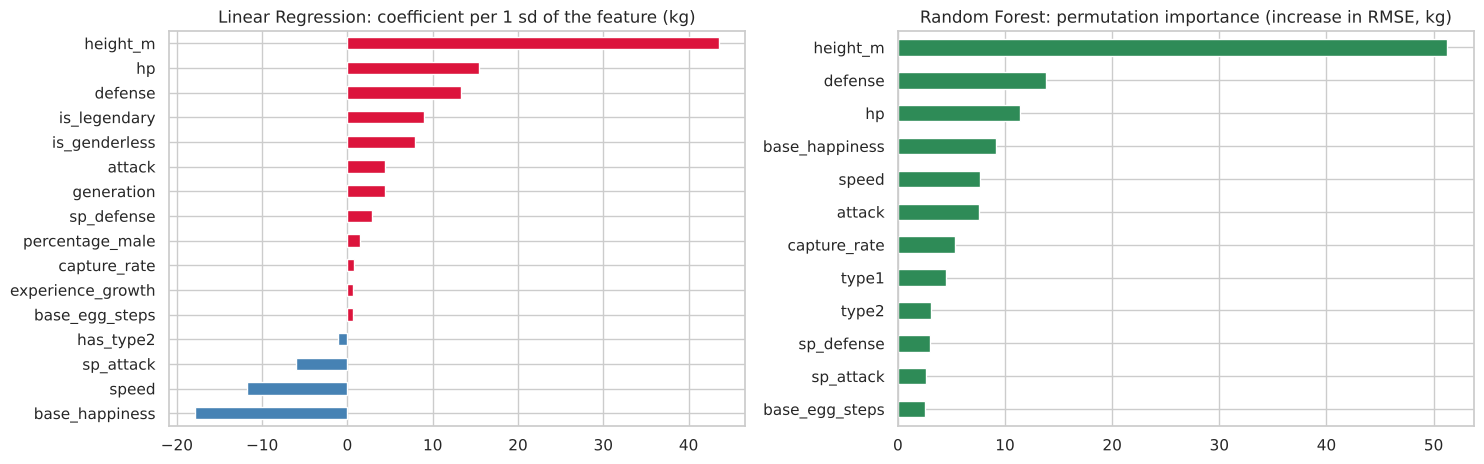

Largest linear coefficients (kg per sd): {'height_m': 43.5, 'base_happiness': -17.9, 'hp': 15.4, 'defense': 13.3, 'speed': -11.8}
Largest permutation importances (kg of RMSE): {'height_m': 51.2, 'defense': 13.8, 'hp': 11.4, 'base_happiness': 9.1}


In [13]:
# Interpretability: what does each model rely on?
pipe_lin = Pipeline([("prep", make_preprocessor(REG_NUM)), ("model", LinearRegression())]).fit(df[REG_NUM + CAT], y_reg)
coef = pd.Series(pipe_lin.named_steps["model"].coef_[:len(REG_NUM)], index=REG_NUM)
pipe_rf = Pipeline([("prep", make_preprocessor(REG_NUM)), ("model", clone(reg_models[BEST_REG]))]).fit(df[REG_NUM + CAT], y_reg)
pi = permutation_importance(pipe_rf, df[REG_NUM + CAT], y_reg, n_repeats=10, random_state=RANDOM_STATE,
                            scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=REG_NUM + CAT)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
coef.sort_values().plot.barh(ax=axes[0], color=np.where(coef.sort_values() > 0, "crimson", "steelblue"))
axes[0].set_title("Linear Regression: coefficient per 1 sd of the feature (kg)")
imp.sort_values().tail(12).plot.barh(ax=axes[1], color="seagreen")
axes[1].set_title(f"{BEST_REG}: permutation importance (increase in RMSE, kg)")
plt.tight_layout(); plt.show()
print("Largest linear coefficients (kg per sd):", coef.reindex(coef.abs().sort_values(ascending=False).index).head(5).round(1).to_dict())
print("Largest permutation importances (kg of RMSE):", imp.sort_values(ascending=False).head(4).round(1).to_dict())

## 4.7 Discussion of the regression models [§2]
* **Relative performance across metrics:** Random Forest wins on MSE/RMSE (75.4), MAE (30.0), MedianAE (10.6) and $R^2$ (0.52). The order of the other models depends on the metric: linear regression is mid-table on RMSE but last on MAE/MedianAE; the shallow tree is the opposite. With heavy-tailed errors, **RMSE ranks the models by their worst few predictions; MAE/MedianAE by their typical predictions** — both views are needed.
* **Assumptions of linear regression:** **linearity — violated** (power law, type-dependent density, 16% negative predictions); **homoscedasticity — violated** (Breusch–Pagan *p* < 0.001, 11× spread ratio); **normality of errors — violated** (kurtosis 41, Jarque–Bera *p* < 0.001); **independence — satisfied** (Durbin–Watson ≈ 2.1 in Pokédex order). Coefficient standard errors and *p*-values of an OLS fit would therefore be unreliable here.
* **Bias–variance:** linear regression and the shallow tree are high-bias (train ≈ validation error, both high); KNN (train RMSE 0), SVR and Gradient Boosting are high-variance (gaps of 47–76 kg); Random Forest has the best balance — bagging lowers the variance of deep trees without adding bias.
* **Sensitivity to outliers and noise:** squared-loss models (OLS, boosting) are pulled toward the extremes — boosting keeps fitting the residuals of Cosmoem-like rows and ends up last. Random Forest isolates extreme Pokémon in their own leaves and averages them away (robust in the centre, but it cannot reach the extremes, hence the positive skew). KNN is sensitive to irrelevant dimensions: 16 standardized features + 37 one-hot columns dilute the distance.
* **When linear models fail, and why:** (i) multiplicative/power-law targets (weight ~ height$^{1.77}$); (ii) interactions — the same height means a different weight for a Steel and a Ghost type; (iii) bounded targets (weight > 0); (iv) a sub-population with different rules (legendaries). The log–log reformulation fixes (i) and (iii) for most Pokémon.
* **When tree-based models help:** thresholds and interactions are learned automatically (type × height, "legendary" × size), predictions stay within the observed range, and no scaling or transformation is needed. Their limitation is the opposite of the linear model's: **no extrapolation** beyond the largest training targets.
* **Interpretability vs. performance:** the linear coefficients are directly readable — +43.5 kg per sd of height; hp (+15.4) and defense (+13.3) also push the weight up, while `base_happiness` (−17.9) and speed (−11.8) push it down (legendaries have happiness 0; fast Pokémon are light). The forest's permutation importance agrees that **height dominates** (+51 kg RMSE when shuffled) followed by defense and hp, but it hides *how* each feature acts. The forest is ~10 kg better in MAE and far less interpretable — an acceptable trade-off for prediction, not for explanation.
* **Preferred model:** **Random Forest** — best on all four error metrics, no impossible predictions, the best bias–variance balance, and stable across folds. If the goal is accuracy on *typical* Pokémon, its log–log version (MAE 27.6, MedianAE 8.0) is better still; we keep the original as the reference because it has the lowest RMSE.
* **What we learned from the modelling stage:** model choice changed the MAE by 35% (30 → 41 kg) but no model exceeded $R^2$ = 0.52; reformulating the target changed the median error by 2.7× (22.9 → 8.6 kg). **The limiting factor is the information in the features (density/material) and the formulation, not the algorithm.**

# 5. Classification Error Analysis [assignment §3]
## 5.1 Problem formulation — and a shortcut we deliberately remove
**Task:** predict `is_legendary` (69 positives, 8.8%) with stratified 10-fold CV.

📘 **Shortcut learning / target leakage.** A feature that is a *consequence of the label* (rather than a cause or an independent property) lets the model "read" the answer instead of learning the concept. In this dataset the **game-design attributes are set by the developers *because* a Pokémon is legendary**: catch rate 3, 30,720 egg steps, base happiness 0, slow experience growth, genderless. We first measure how much they give away.

In [14]:
y_clf = df[CLF_TARGET].values

def cv_classification(estimator, num_cols, cv=skf):
    X = df[num_cols + CAT]
    pipe = Pipeline([("prep", make_preprocessor(num_cols)), ("model", estimator)])
    oof, fold_id, train_auc = np.zeros(len(X)), np.zeros(len(X), int), []
    for f, (tr, va) in enumerate(cv.split(X, y_clf)):
        m = clone(pipe).fit(X.iloc[tr], y_clf[tr])
        oof[va] = m.predict_proba(X.iloc[va])[:, 1]; fold_id[va] = f
        train_auc.append(roc_auc_score(y_clf[tr], m.predict_proba(X.iloc[tr])[:, 1]))
    return oof, fold_id, float(np.mean(train_auc))

clf_models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, C=1.0),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=RANDOM_STATE),
    "KNN (bonus)": KNeighborsClassifier(n_neighbors=25, weights="distance"),
}

# ---- Shortcut experiment: battle/body stats only vs. + game-design metadata ----
rows = []
for m in ["Logistic Regression", "Random Forest"]:
    for label, cols in [("stats only", CLF_NUM), ("stats + game-design metadata", CLF_NUM + SHORTCUTS)]:
        p, _, _ = cv_classification(clf_models[m], cols); pr = (p >= .5).astype(int)
        rows.append({"model": m, "features": label, "AUC": roc_auc_score(y_clf, p), "F1": f1_score(y_clf, pr),
                     "MCC": matthews_corrcoef(y_clf, pr), "errors (of 781)": int((pr != y_clf).sum())})
display(pd.DataFrame(rows).set_index(["model", "features"]))
leg = df.is_legendary == 1
print(f"capture_rate = 3 for {100 * (df.capture_rate[leg] == 3).mean():.0f}% of legendary vs. "
      f"{100 * (df.capture_rate[~leg] == 3).mean():.1f}% of regular Pokémon; "
      f"base_egg_steps = 30720 for {100 * (df.base_egg_steps[leg] == 30720).mean():.0f}% vs. "
      f"{100 * (df.base_egg_steps[~leg] == 30720).mean():.1f}%")

AUC    F1   MCC  errors (of 781)
model               features                                                       
Logistic Regression stats only                   0.961 0.634 0.609               45
                    stats + game-design metadata 0.997 0.942 0.936                8
Random Forest       stats only                   0.975 0.484 0.521               49
                    stats + game-design metadata 0.999 0.971 0.969                4

capture_rate = 3 for 75% of legendary vs. 0.7% of regular Pokémon; base_egg_steps = 30720 for 67% vs. 0.3%


🔎 **With the metadata the task is trivial — and uninformative**
* `capture_rate = 3` for **75% of legendaries vs. 0.7% of regular Pokémon**; `base_egg_steps = 30,720` for **67% vs. 0.3%**.
* With these attributes, Random Forest reaches AUC 0.999 and MCC 0.97 with **4 errors out of 781**; logistic regression makes 8. Such a model only learns the game's bookkeeping rule, and there would be nothing left to analyse.
* **Formulation used from now on:** *"Can we recognise a legendary Pokémon from its body and its battle stats?"* — height, weight, the six base stats, `has_type2`, generation and the two types (stats only: 45–49 errors). This question is meaningful (would a new Pokémon "look" legendary?) and its errors are informative.

## 5.2 Models
Same protocol as for regression: identical features for every model, fixed hyperparameters (logistic regression C = 1; tree depth 6 / leaf 20; forest 300 trees; boosting 300 iterations, learning rate 0.05; KNN k = 25 distance-weighted), out-of-fold probabilities from stratified 10-fold CV.

In [15]:
clf_oof, clf_train_auc = {}, {}
for m, est in clf_models.items():
    clf_oof[m], fold_id, clf_train_auc[m] = cv_classification(est, CLF_NUM)

rows = []
for m, p in clf_oof.items():
    pr = (p >= .5).astype(int)
    fold_auc = [roc_auc_score(y_clf[fold_id == f], p[fold_id == f]) for f in range(K_FOLDS)]
    rows.append({"model": m, "AUC": roc_auc_score(y_clf, p), "AUC fold sd": np.std(fold_auc), "train AUC": clf_train_auc[m],
                 "accuracy": accuracy_score(y_clf, pr), "balanced acc.": balanced_accuracy_score(y_clf, pr),
                 "precision": precision_score(y_clf, pr, zero_division=0), "recall": recall_score(y_clf, pr),
                 "F1": f1_score(y_clf, pr), "MCC": matthews_corrcoef(y_clf, pr)})
clf_results = pd.DataFrame(rows).set_index("model").sort_values("AUC", ascending=False)
display(clf_results)
BEST_CLF = clf_results.index[0]
p_best = clf_oof[BEST_CLF]; pred_best = (p_best >= .5).astype(int)
print(f"Auto-summary: best by AUC = {BEST_CLF}; best by F1 at 0.5 = {clf_results.F1.idxmax()}; "
      f"majority-class baseline accuracy = {1 - y_clf.mean():.3f}")

,AUC,AUC fold sd,train AUC,accuracy,balanced acc.,precision,recall,F1,MCC
model,,,,,,,,,
Gradient Boosting,0.979,0.015,1.000,0.955,0.792,0.854,0.594,0.701,0.691
Random Forest,0.975,0.018,1.000,0.937,0.665,0.885,0.333,0.484,0.521
KNN (bonus),0.961,0.026,1.000,0.930,0.628,0.818,0.261,0.396,0.438
Logistic Regression,0.961,0.035,0.978,0.942,0.772,0.722,0.565,0.634,0.609
Decision Tree,0.853,0.080,0.956,0.917,0.673,0.542,0.377,0.444,0.409


Auto-summary: best by AUC = Gradient Boosting; best by F1 at 0.5 = Gradient Boosting; majority-class baseline accuracy = 0.912


🔎 **Comparison (stats-only features, threshold 0.5)**
* **Accuracy is misleading:** a model that always answers "regular" scores **0.912**. All models are only 0.5–4 points above it; **MCC, F1, balanced accuracy and AUC** are the relevant metrics for a rare class.
* **Gradient Boosting is best:** AUC 0.979 (fold sd 0.015), F1 0.701, MCC 0.691, precision 0.854, recall 0.594. It is used for the detailed analysis below.
* **AUC and F1 disagree:** Random Forest has almost the same AUC (0.975) but F1 only 0.484 (recall 0.333). AUC measures the **ranking** of Pokémon by probability; F1 depends on the **threshold**. The forest ranks well but its probabilities are compressed (averaging 300 trees rarely gives > 0.5 for a minority class), so 0.5 is a bad threshold for it — see 5.6.
* **Logistic regression** (AUC 0.961, F1 0.634, MCC 0.609, train AUC 0.978) is close to the ensembles and almost free of overfitting; tree ensembles and KNN have train AUC = 1.000 (they memorize), yet still generalize well in ranking terms.
* **The single Decision Tree is clearly worst** (AUC 0.853, fold sd 0.080 — the least stable model).

## 5.3 Confusion matrix analysis
📘 For a rare positive class: **FP** = a regular Pokémon called legendary; **FN** = a legendary missed. FPR $=FP/(FP+TN)$, FNR $=FN/(FN+TP)$ = 1 − recall, precision $=TP/(TP+FP)$. We list *every* FP and the most confident FNs, and look for **regions** (generation, type, overall strength) where the model fails systematically. `base_total` (the sum of the stats) is not a model input — it is used only to describe the errors.

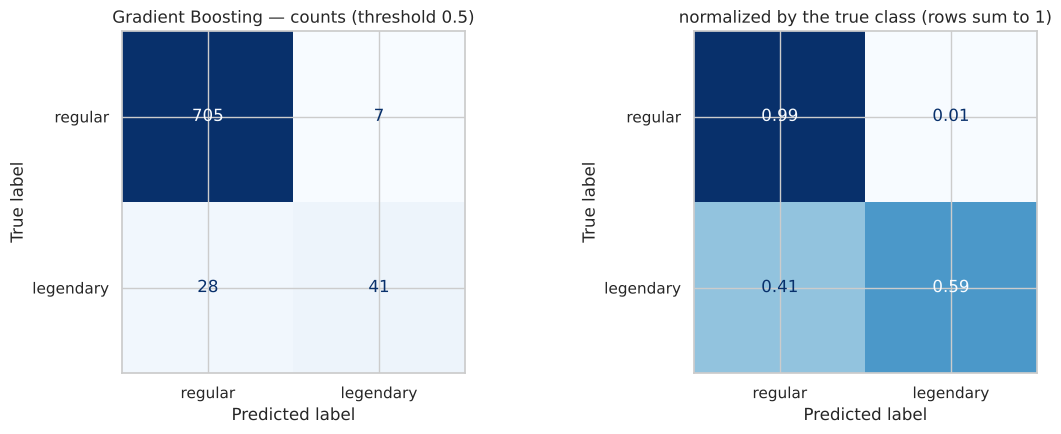

TN=705  FP=7  FN=28  TP=41  |  FPR = 0.010   FNR = 0.406   precision = 0.854
False positives (regular Pokémon predicted legendary):


,name,classfication,type1,generation,height_m,weight_kg,hp,attack,defense,sp_attack,sp_defense,speed,base_total,P_legendary
616,Hydreigon,Brutal Pokémon,dark,5,1.800,160.000,92,105,90,125,90,98,600,0.994
763,Kommo-o,Scaly Pokémon,dragon,7,1.600,78.200,75,110,125,100,105,85,600,0.992
357,Metagross,Iron Leg Pokémon,steel,3,1.600,550.000,80,145,150,105,110,110,700,0.984
229,Tyranitar,Armor Pokémon,rock,2,2.000,202.000,100,164,150,95,120,71,700,0.950
210,Houndoom,Dark Pokémon,dark,2,1.400,35.000,75,90,90,140,90,115,600,0.938
478,Serperior,Regal Pokémon,grass,5,3.300,63.000,75,75,95,75,95,113,528,0.754
426,Garchomp,Mach Pokémon,dragon,4,1.900,95.000,108,170,115,120,95,92,700,0.592


False negatives (legendary Pokémon missed) — 12 with the lowest probability:


,name,classfication,type1,generation,height_m,weight_kg,hp,attack,defense,sp_attack,sp_defense,speed,base_total,P_legendary
768,Cosmog,Nebula Pokémon,psychic,7,0.200,0.100,43,29,31,29,31,37,200,0.000
778,Guzzlord,Junkivore Pokémon,dark,7,5.500,888.000,223,101,53,97,53,43,570,0.000
766,Tapu Bulu,Land Spirit Pokémon,grass,7,1.900,45.500,70,130,115,85,95,75,570,0.002
775,Xurkitree,Glowing Pokémon,electric,7,3.800,100.000,83,89,71,173,71,83,570,0.002
630,Genesect,Paleozoic Pokémon,bug,5,1.500,82.500,71,120,95,120,95,99,600,0.005
359,Regice,Iceberg Pokémon,ice,3,1.800,175.000,80,50,100,100,200,50,580,0.006
358,Regirock,Rock Peak Pokémon,rock,3,1.700,230.000,80,100,200,50,100,50,580,0.006
773,Buzzwole,Swollen Pokémon,bug,7,2.400,333.600,107,139,139,53,53,79,570,0.015
769,Cosmoem,Protostar Pokémon,psychic,7,0.100,999.900,43,29,131,29,131,37,400,0.015
626,Landorus,Abundance Pokémon,ground,5,1.500,68.000,89,145,90,105,80,91,600,0.021


gen,1,2,3,4,5,6,7
n,133.000,100.000,135.000,107.000,156.000,71.000,79.000
legendary,5.000,6.000,10.000,13.000,13.000,5.000,17.000
FN,0.000,1.000,3.000,3.000,6.000,1.000,14.000
FP,0.000,2.000,1.000,1.000,2.000,0.000,1.000
recall %,100.000,83.333,70.000,76.923,53.846,80.000,17.647
share of all errors %,0.000,8.571,11.429,11.429,22.857,2.857,42.857


base_total (sum of stats, not a model input) by outcome:


,mean,min,50%,max
FN,561.071,200.000,580.000,600.000
FP,632.571,528.000,600.000,700.000
TP,650.683,580.000,680.000,780.000
TN,408.591,180.000,413.000,700.000


In [16]:
cm = confusion_matrix(y_clf, pred_best); tn, fp, fn, tp = cm.ravel()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["regular", "legendary"]).plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title(f"{BEST_CLF} — counts (threshold 0.5)")
ConfusionMatrixDisplay(confusion_matrix(y_clf, pred_best, normalize="true"), display_labels=["regular", "legendary"]).plot(
    ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False)
axes[1].set_title("normalized by the true class (rows sum to 1)")
plt.tight_layout(); plt.show()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}  |  FPR = {fp / (fp + tn):.3f}   FNR = {fn / (fn + tp):.3f}   "
      f"precision = {tp / (tp + fp):.3f}")

err_type = np.select([(y_clf == 1) & (pred_best == 0), (y_clf == 0) & (pred_best == 1)], ["FN", "FP"], "correct")
show = ["name", "classfication", "type1", "generation", "height_m", "weight_kg"] + STATS
err_view = df[show].assign(base_total=df.base_total, P_legendary=p_best)
print("False positives (regular Pokémon predicted legendary):")
display(err_view[err_type == "FP"].sort_values("P_legendary", ascending=False))
print("False negatives (legendary Pokémon missed) — 12 with the lowest probability:")
display(err_view[err_type == "FN"].sort_values("P_legendary").head(12))

g = pd.DataFrame({"gen": df.generation, "type": df.type1, "y": y_clf, "err": err_type})
by_gen = g.groupby("gen").agg(n=("y", "size"), legendary=("y", "sum"),
                              FN=("err", lambda s: (s == "FN").sum()), FP=("err", lambda s: (s == "FP").sum()))
by_gen["recall %"] = 100 * (1 - by_gen.FN / by_gen.legendary)
by_gen["share of all errors %"] = 100 * (by_gen.FN + by_gen.FP) / (fn + fp)
display(by_gen.T)
base_total_cmp = pd.DataFrame({grp: df.base_total[err_type == grp].describe()[["mean", "min", "50%", "max"]]
                               for grp in ["FN", "FP"]})
base_total_cmp["TP"] = df.base_total[(y_clf == 1) & (pred_best == 1)].describe()[["mean", "min", "50%", "max"]]
base_total_cmp["TN"] = df.base_total[(y_clf == 0) & (pred_best == 0)].describe()[["mean", "min", "50%", "max"]]
print("base_total (sum of stats, not a model input) by outcome:")
display(base_total_cmp.T)

🔎 **Interpreting the confusion matrix**
* **TN = 705, FP = 7, FN = 28, TP = 41.** The model almost never raises a false alarm (**FPR 1.0%**, precision 0.85) but **misses 41% of the legendaries** (FNR 0.406). At threshold 0.5 it is a conservative classifier.
* **Which error is more critical?** It depends on the use. For a **player/collector who wants to find every legendary** (or a tournament that must detect banned legendaries), an FN is worse — a missed legendary is a lost opportunity / a rule violation, whereas an FP only costs a manual check. For an **automatic restriction** (e.g., excluding Pokémon labelled legendary from a competition), an FP is worse — a legitimate Pokémon would be banned. We consider **FN the more critical error** (the class of interest is rare and valuable), which argues for a lower threshold (5.6).
* **The False Positives are not random — they are a data-quality finding:**
  * **Hydreigon and Kommo-o** (base total 600) are the classic **"pseudo-legendaries"**: regular Pokémon designed with legendary-level stats. They are *indistinguishable from legendaries by stats* — an irreducible error for this formulation.
  * **Serperior** (528, P = 0.75) is the only "ordinary" false positive.
  * **Tyranitar, Metagross, Garchomp (700) and Houndoom (600)** carry the stats of their **Mega Evolution**, not their regular form (e.g. Tyranitar's regular base total is 600; 100/164/150/95/120/71 = 700 are Mega Tyranitar's stats). The scraper mixed forms — a **data-quality error** that pushes these rows into the legendary region.
* **The False Negatives are "weak" or "unusual" legendaries:** Cosmog (base total **200**) and Cosmoem (400) are baby legendaries; **Regirock and Regice** have one extreme stat (defense or sp. defense 200) and weak others; the **Ultra Beasts** (Guzzlord, Xurkitree, Buzzwole, Nihilego, Kartana, Pheromosa) and **Tapus** have 570 — the stat level of strong regular Pokémon. In numbers: FN have mean base total 561 (max 600), FP 633, TP 651, TN 409 — **the FN and FP overlap exactly in the 570–600 band**.
* **Systematic failure region: generation 7.** Recall is 100% in generation 1 but **17.6% in generation 7** (14 of 17 legendaries missed); generation 7 alone accounts for **43% of all errors** while holding 10% of the data. Generation 7 introduced "legendaries" (Ultra Beasts, Tapus, the Cosmog line) that are legendary by story, not by stats — the **concept itself drifted**.
* **Insight:** the model has learned "legendary ≈ very strong". That rule is correct for generations 1–6 and wrong for generation 7 and for pseudo-legendaries/Megas. The errors come from **the data (mixed Mega stats) and the formulation (a story-based label)**, not from the algorithm.

## 5.4 Probability-based analysis — high-confidence errors
📘 **Confidence** $=\max(p, 1-p)$. A well-behaved classifier is uncertain (probability near 0.5) where it is wrong. **High-confidence errors** (wrong with confidence ≥ 0.8) indicate examples that genuinely look like the other class — a data or formulation problem that recalibration or more training cannot fix. The **reliability curve** compares the predicted probability with the observed frequency in probability bins.

,count,mean,std,min,25%,50%,75%,max
outcome,,,,,,,,
correct,746.000,0.991,0.042,0.564,1.000,1.000,1.000,1.000
incorrect,35.000,0.848,0.156,0.519,0.743,0.895,0.988,1.000


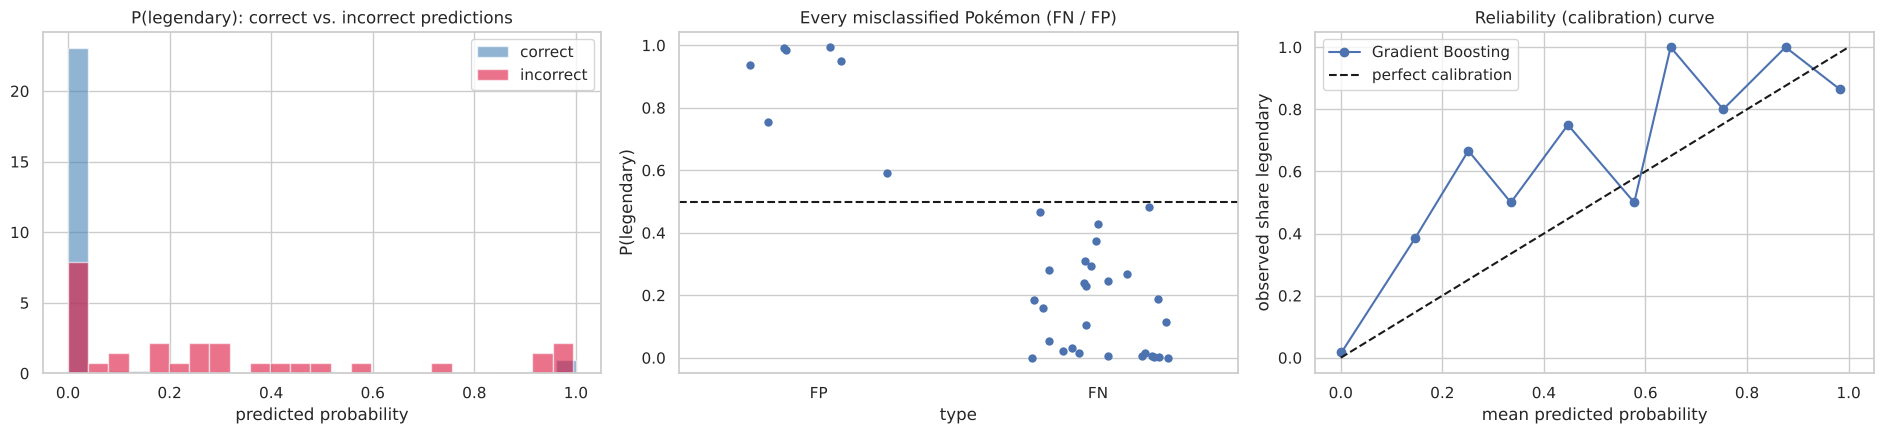

High-confidence errors (wrong with confidence ≥ 0.8): 22 of 35 errors (63%); median confidence of errors 0.89


,name,classfication,type1,generation,true,P_legendary,base_total
768,Cosmog,Nebula Pokémon,psychic,7,1,0.000,200
778,Guzzlord,Junkivore Pokémon,dark,7,1,0.000,570
766,Tapu Bulu,Land Spirit Pokémon,grass,7,1,0.002,570
775,Xurkitree,Glowing Pokémon,electric,7,1,0.002,570
630,Genesect,Paleozoic Pokémon,bug,5,1,0.005,600
359,Regice,Iceberg Pokémon,ice,3,1,0.006,580
358,Regirock,Rock Peak Pokémon,rock,3,1,0.006,580
773,Buzzwole,Swollen Pokémon,bug,7,1,0.015,570
769,Cosmoem,Protostar Pokémon,psychic,7,1,0.015,400
626,Landorus,Abundance Pokémon,ground,5,1,0.021,600


In [17]:
correct = pred_best == y_clf
conf = np.maximum(p_best, 1 - p_best)
prob_df = pd.DataFrame({"P(legendary)": p_best, "confidence": conf, "outcome": np.where(correct, "correct", "incorrect"),
                        "type": err_type})
display(prob_df.groupby("outcome").confidence.describe())

fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
for lab, col in [("correct", "steelblue"), ("incorrect", "crimson")]:
    axes[0].hist(prob_df["P(legendary)"][prob_df.outcome == lab], bins=25, alpha=.6, density=True, color=col, label=lab)
axes[0].set(title="P(legendary): correct vs. incorrect predictions", xlabel="predicted probability"); axes[0].legend()
sns.stripplot(data=prob_df[prob_df.type != "correct"], x="type", y="P(legendary)", ax=axes[1], size=6, jitter=.25)
axes[1].axhline(.5, color="k", ls="--"); axes[1].set_title("Every misclassified Pokémon (FN / FP)")
frac, mean_p = calibration_curve(y_clf, p_best, n_bins=10, strategy="uniform")
axes[2].plot(mean_p, frac, "o-", label=BEST_CLF); axes[2].plot([0, 1], [0, 1], "k--", label="perfect calibration")
axes[2].set(title="Reliability (calibration) curve", xlabel="mean predicted probability", ylabel="observed share legendary")
axes[2].legend(); plt.tight_layout(); plt.show()

hc = (~correct) & (conf >= .8)
print(f"High-confidence errors (wrong with confidence ≥ 0.8): {hc.sum()} of {(~correct).sum()} errors "
      f"({100 * hc.sum() / (~correct).sum():.0f}%); median confidence of errors {np.median(conf[~correct]):.2f}")
display(df.loc[hc, ["name", "classfication", "type1", "generation"]].assign(
    true=y_clf[hc], P_legendary=p_best[hc], base_total=df.base_total[hc]).sort_values("P_legendary"))

🔎 **The model is confidently wrong**
* Correct predictions have mean confidence 0.991; errors **0.848 (median 0.89)** — far from 0.5.
* **22 of the 35 errors (63%) have confidence ≥ 0.8.** The FN strip-plot shows most missed legendaries at P(legendary) < 0.2 (Cosmog, Guzzlord, Tapu Bulu, Xurkitree, Genesect, Regice, Regirock at ≤ 0.006), and the FP at > 0.9 (Hydreigon 0.994, Kommo-o 0.992, Metagross 0.984, Tyranitar 0.950, Houndoom 0.938).
* **Why this matters:** these are not borderline cases that a better threshold or more trees would fix — in the feature space they **are** surrounded by the other class. This confirms the diagnosis of 5.3: mislabeled-looking rows (Mega stats) and legendaries whose stats are ordinary.
* **Calibration:** the reliability curve lies **above the diagonal for predicted probabilities between ≈ 0.1 and 0.5** — Pokémon predicted at 0.15 are legendary ≈ 38% of the time, those at 0.25 ≈ 67% (bins are small, so the curve is noisy). The model **under-estimates** the probability in this range, i.e. it is too sure that ambiguous strong Pokémon are regular. This is exactly why the default threshold 0.5 is too strict and the optimal threshold is ≈ 0.2 (5.6). For ranking the probabilities are excellent (AUC 0.98); as absolute probabilities they would need recalibration (e.g. isotonic).

## 5.5 Error as a function of the features — regions prone to misclassification
We compare the distribution of every feature for correct vs. incorrect predictions (density plots; the Kolmogorov–Smirnov statistic measures the maximum gap between the two distributions) and the means of FN, FP and all legendaries. Then we locate the errors along the overall strength axis (deciles of `base_total`).

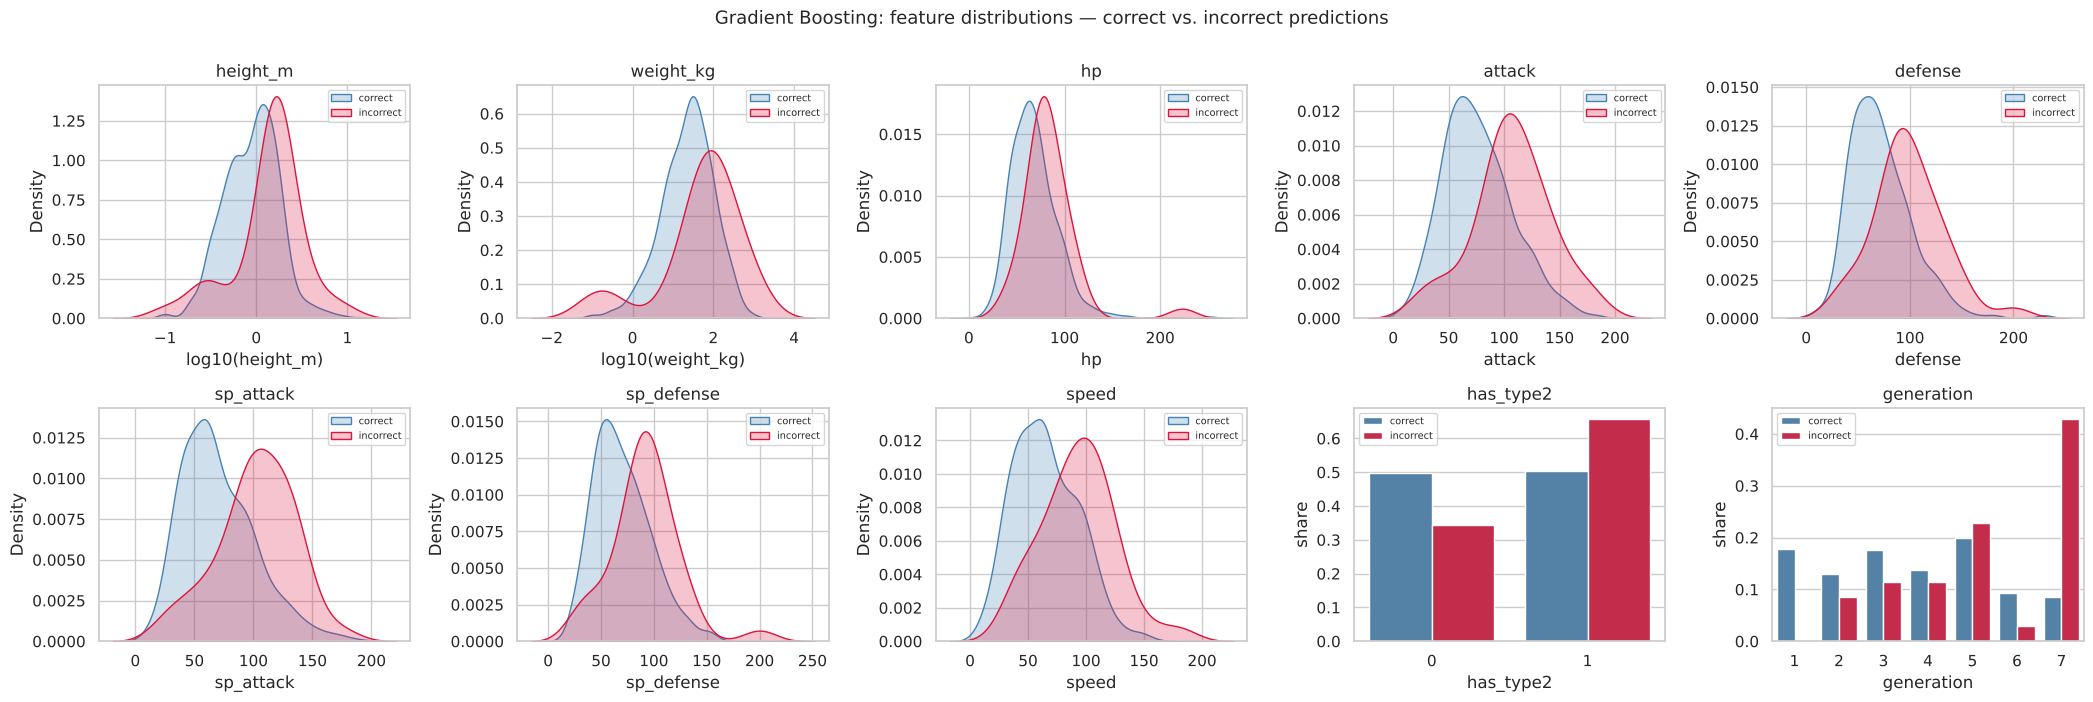

,mean correct,mean incorrect,mean FN,mean FP,mean all legendary,KS statistic,KS p-value
feature,,,,,,,
sp_attack,70.214,101.857,100.179,108.571,112.942,0.492,0.000
attack,76.332,106.714,102.714,122.714,108.623,0.474,0.000
defense,71.819,98.229,93.679,116.429,99.971,0.445,0.000
hp,68.453,83.971,83.357,86.429,95.652,0.442,0.000
height_m,1.132,1.854,1.832,1.943,2.281,0.442,0.000
sp_defense,70.052,91.600,89.321,100.714,101.478,0.423,0.000
speed,65.025,93.000,91.821,97.714,95.652,0.400,0.000
weight_kg,55.917,177.786,179.975,169.029,199.351,0.386,0.000
generation,3.673,5.286,5.607,4.000,4.536,0.343,0.001


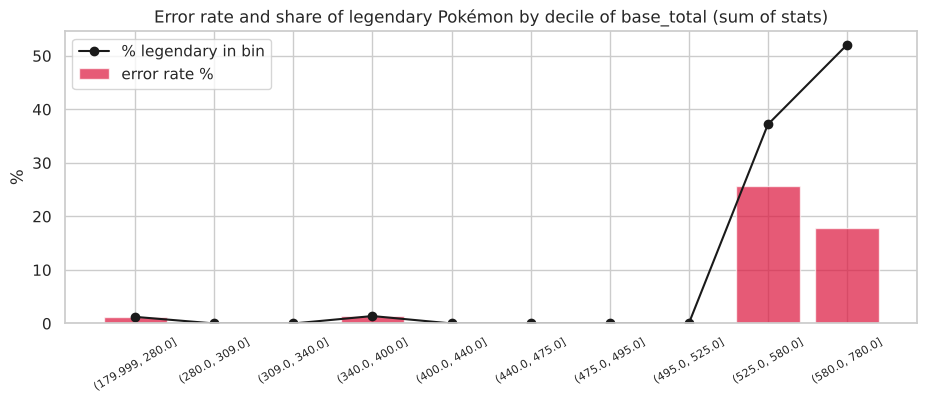

base_total decile,"(179.999, 280.0]","(280.0, 309.0]","(309.0, 340.0]","(340.0, 400.0]","(400.0, 440.0]","(440.0, 475.0]","(475.0, 495.0]","(495.0, 525.0]","(525.0, 580.0]","(580.0, 780.0]"
n,81.000,76.000,85.000,72.000,82.000,73.000,82.000,79.000,78.000,73.000
error_rate,0.012,0.000,0.000,0.014,0.000,0.000,0.000,0.000,0.256,0.178
share_legendary,0.012,0.000,0.000,0.014,0.000,0.000,0.000,0.000,0.372,0.521


In [18]:
feats = CLF_NUM
fig, axes = plt.subplots(2, 5, figsize=(21, 7))
for ax, f in zip(axes.ravel(), feats):
    t = pd.DataFrame({"x": df[f], "outcome": prob_df.outcome})
    if t.x.nunique() <= 10:
        sh = t.groupby("outcome").x.value_counts(normalize=True).rename("share").reset_index()
        sns.barplot(data=sh, x="x", y="share", hue="outcome", ax=ax, palette=["steelblue", "crimson"])
    else:
        xx = np.log10(t.x) if f in ["height_m", "weight_kg"] else t.x
        for lab, col in [("correct", "steelblue"), ("incorrect", "crimson")]:
            sns.kdeplot(xx[t.outcome == lab], ax=ax, fill=True, color=col, label=lab, common_norm=False)
    ax.set_xlabel(f"log10({f})" if f in ["height_m", "weight_kg"] else f)
    ax.set_title(f); ax.legend(fontsize=7)
fig.suptitle(f"{BEST_CLF}: feature distributions — correct vs. incorrect predictions", y=1.0, fontsize=13)
plt.tight_layout(); plt.show()

rows = []
for f in feats:
    a, b = df.loc[correct, f], df.loc[~correct, f]
    rows.append({"feature": f, "mean correct": a.mean(), "mean incorrect": b.mean(),
                 "mean FN": df.loc[err_type == "FN", f].mean(), "mean FP": df.loc[err_type == "FP", f].mean(),
                 "mean all legendary": df.loc[y_clf == 1, f].mean(),
                 "KS statistic": stats.ks_2samp(a, b).statistic, "KS p-value": stats.ks_2samp(a, b).pvalue})
display(pd.DataFrame(rows).set_index("feature").sort_values("KS statistic", ascending=False))

# where are errors concentrated? error rate by decile of the (not used) base_total, and by the model's own score
bt = pd.qcut(df.base_total, 10, duplicates="drop")
err_bt = pd.DataFrame({"base_total decile": bt, "err": ~correct, "leg": y_clf}).groupby("base_total decile", observed=True).agg(
    n=("err", "size"), error_rate=("err", "mean"), share_legendary=("leg", "mean"))
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(range(len(err_bt)), 100 * err_bt.error_rate, color="crimson", alpha=.7, label="error rate %")
ax.plot(range(len(err_bt)), 100 * err_bt.share_legendary, "ko-", label="% legendary in bin")
ax.set_xticks(range(len(err_bt))); ax.set_xticklabels([str(i) for i in err_bt.index], rotation=30, fontsize=8)
ax.set(title="Error rate and share of legendary Pokémon by decile of base_total (sum of stats)", ylabel="%"); ax.legend()
plt.show()
display(err_bt.T)

🔎 **Errors live in the "strong Pokémon" zone**
* **Incorrect predictions are much stronger than correct ones:** sp. attack 102 vs. 70, attack 107 vs. 76, defense 98 vs. 72, height 1.85 vs. 1.13 m (KS statistic 0.39–0.49, all *p* < 0.001). Only `has_type2` does not differ significantly (KS *p* = 0.36).
* **FN vs. FP:** the missed legendaries are *slightly weaker* than the average legendary (attack 103 vs. 109, hp 83 vs. 96), while the false positives are *stronger* than it (attack 123, defense 116). Both groups sit on the boundary from opposite sides.
* **Errors by strength decile:** in the **8 lowest base-total deciles the error rate is 0–1.4%** (no legendaries there, nothing to confuse). All the difficulty is in the **top two deciles: 25.6% errors at base total 525–580 and 17.8% at 580–780**, exactly where legendaries (37% and 52% of these bins) and strong regular Pokémon mix. The model "fails systematically" in one well-defined region: **strong, non-legendary-looking legendaries and legendary-looking regular Pokémon**.
* **Generation** is the second region (43% of errors in generation 7, see 5.3).
* **Guidance for improvement:** features that separate the two groups *inside* the strong zone — e.g. the **balance of the stats** (legendaries tend to have even stats; Regirock/Regice and Ultra Beasts do not), a flag for Mega/alternate forms, or the story-related game attributes if the goal allows them.

## 5.6 Threshold sensitivity analysis
📘 For thresholds $t = 0.1, \dots, 0.9$: **precision**, **recall**, $F_1 = \frac{2PR}{P+R}$, **MCC** $=\frac{TP\cdot TN-FP\cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}$ (a balanced correlation in $[-1,1]$, robust to imbalance), and the sd of F1/MCC across the 10 folds (**stability**). $F_\beta=(1+\beta^2)\frac{PR}{\beta^2P+R}$ weighs recall $\beta$ times as much as precision; we plot it as a function of $\beta$ for several thresholds. **AUC-ROC** summarizes the ranking over all thresholds.

,precision,recall,F1,MCC,FP,FN,F1 fold sd,MCC fold sd
threshold,,,,,,,,
0.100,0.731,0.826,0.776,0.754,21,12,0.158,0.170
0.200,0.800,0.754,0.776,0.756,13,17,0.148,0.154
0.300,0.821,0.667,0.736,0.718,10,23,0.141,0.143
0.400,0.846,0.638,0.727,0.713,8,25,0.177,0.175
0.500,0.854,0.594,0.701,0.691,7,28,0.172,0.159
0.600,0.870,0.580,0.696,0.689,6,29,0.172,0.160
0.700,0.867,0.565,0.684,0.678,6,30,0.169,0.158
0.800,0.875,0.507,0.642,0.644,5,34,0.160,0.141
0.900,0.865,0.464,0.604,0.610,5,37,0.163,0.142


AUC-ROC (threshold-free) = 0.979;  best F1 at t = 0.2, best MCC at t = 0.2


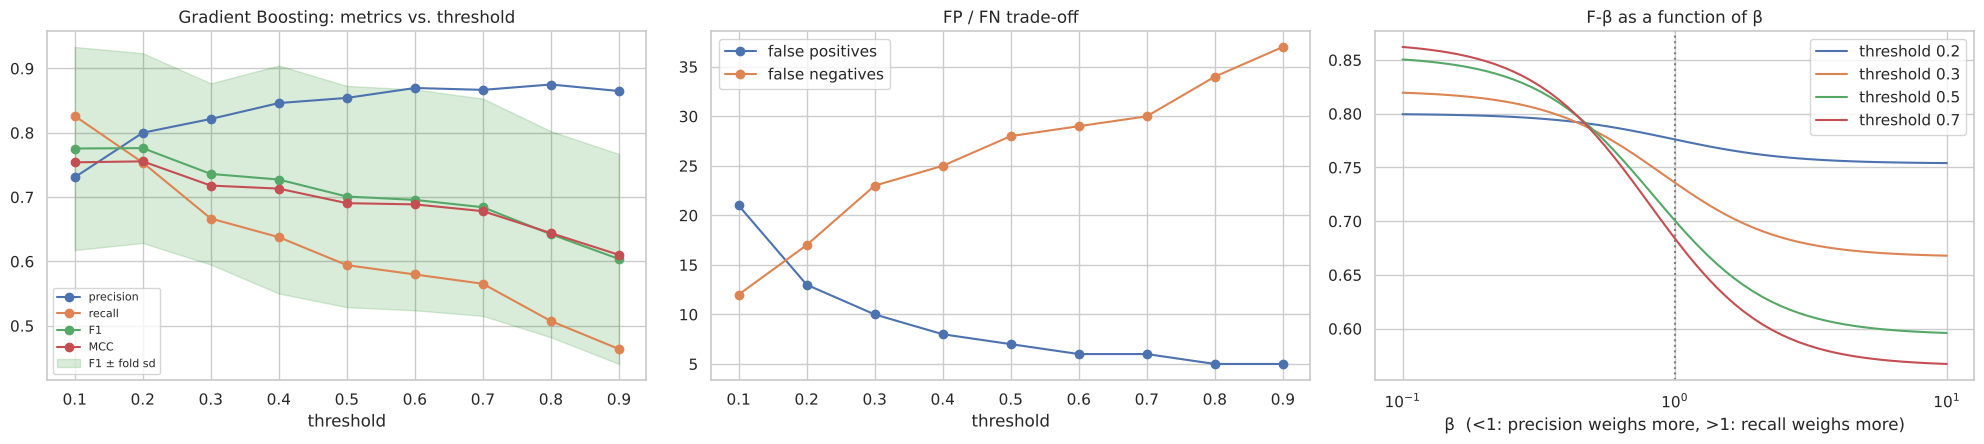

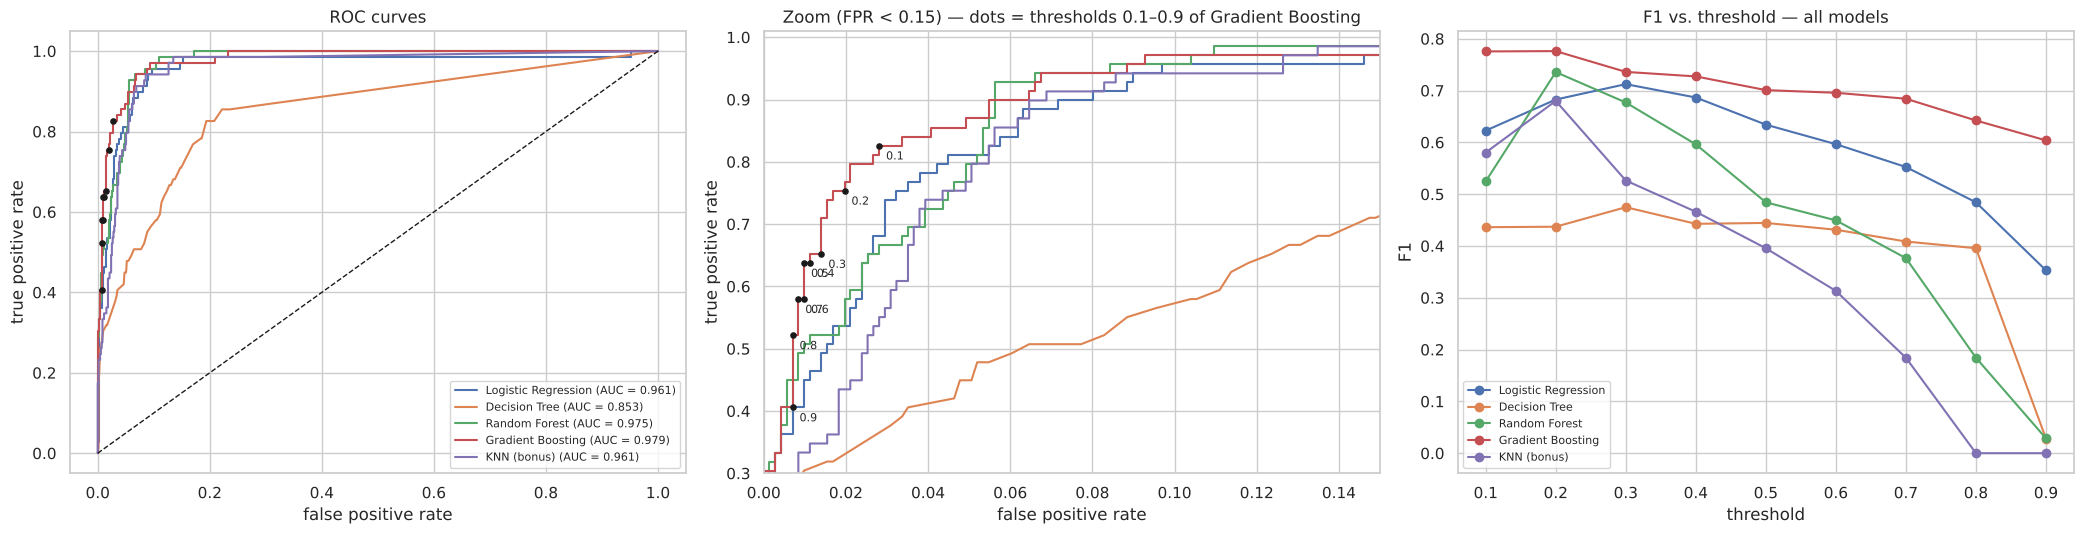

In [19]:
THRESHOLDS = np.round(np.arange(.1, 1.0, .1), 1)
def metrics_at(y, p, t):
    pr = (p >= t).astype(int); tn_, fp_, fn_, tp_ = confusion_matrix(y, pr, labels=[0, 1]).ravel()
    return {"precision": precision_score(y, pr, zero_division=0), "recall": recall_score(y, pr),
            "F1": f1_score(y, pr, zero_division=0), "MCC": matthews_corrcoef(y, pr), "FP": fp_, "FN": fn_}

thr_rows = []
for t in THRESHOLDS:
    row = {"threshold": t, **metrics_at(y_clf, p_best, t)}
    per_fold = [metrics_at(y_clf[fold_id == f], p_best[fold_id == f], t) for f in range(K_FOLDS)]
    row["F1 fold sd"] = np.std([d["F1"] for d in per_fold]); row["MCC fold sd"] = np.std([d["MCC"] for d in per_fold])
    thr_rows.append(row)
thr = pd.DataFrame(thr_rows).set_index("threshold")
display(thr)
print(f"AUC-ROC (threshold-free) = {roc_auc_score(y_clf, p_best):.3f};  best F1 at t = {thr.F1.idxmax()}, "
      f"best MCC at t = {thr.MCC.idxmax()}")

fig, axes = plt.subplots(1, 3, figsize=(20, 4.6))
for c in ["precision", "recall", "F1", "MCC"]:
    axes[0].plot(thr.index, thr[c], "o-", label=c)
axes[0].fill_between(thr.index, thr.F1 - thr["F1 fold sd"], thr.F1 + thr["F1 fold sd"], alpha=.15, color="green",
                     label="F1 ± fold sd")
axes[0].set(title=f"{BEST_CLF}: metrics vs. threshold", xlabel="threshold"); axes[0].legend(fontsize=8)
axes[1].plot(thr.index, thr.FP, "o-", label="false positives"); axes[1].plot(thr.index, thr.FN, "o-", label="false negatives")
axes[1].set(title="FP / FN trade-off", xlabel="threshold"); axes[1].legend()
betas = np.logspace(-1, 1, 60)
for t in [.2, .3, .5, .7]:
    pr = (p_best >= t).astype(int)
    axes[2].plot(betas, [fbeta_score(y_clf, pr, beta=b) for b in betas], label=f"threshold {t}")
axes[2].axvline(1, color="gray", ls=":")
axes[2].set(xscale="log", title="F-β as a function of β", xlabel="β  (<1: precision weighs more, >1: recall weighs more)")
axes[2].legend(); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
for m, p in clf_oof.items():
    fpr, tpr, _ = roc_curve(y_clf, p)
    for ax in axes[:2]:
        ax.plot(fpr, tpr, label=f"{m} (AUC = {roc_auc_score(y_clf, p):.3f})")
fpr, tpr, th = roc_curve(y_clf, p_best)
for t in THRESHOLDS:
    i = np.argmin(np.abs(th - t))
    for ax in axes[:2]:
        ax.scatter(fpr[i], tpr[i], c="k", s=14, zorder=5)
    axes[1].annotate(f"{t}", (fpr[i], tpr[i]), fontsize=8, xytext=(5, -10), textcoords="offset points")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="ROC curves", xlabel="false positive rate", ylabel="true positive rate"); axes[0].legend(fontsize=8, loc="lower right")
axes[1].set(xlim=(0, .15), ylim=(.3, 1.01), title=f"Zoom (FPR < 0.15) — dots = thresholds 0.1–0.9 of {BEST_CLF}",
            xlabel="false positive rate", ylabel="true positive rate")
for m, p in clf_oof.items():
    axes[2].plot(THRESHOLDS, [f1_score(y_clf, (p >= t).astype(int), zero_division=0) for t in THRESHOLDS], "o-", label=m)
axes[2].set(title="F1 vs. threshold — all models", xlabel="threshold", ylabel="F1"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

🔎 **Trade-off, stable and unstable regions**
* **FP/FN trade-off:** lowering the threshold from 0.5 to **0.2** removes 11 false negatives (28 → 17) at the cost of 6 more false positives (7 → 13); at 0.1 the counts are 12 FN / 21 FP. Above 0.5 the FP count barely changes (7 → 5) while FN keep rising (28 → 37): **high thresholds buy almost nothing**.
* **Best operating point:** F1 and MCC both peak at **t = 0.2** (F1 0.776, MCC 0.756, precision 0.80, recall 0.75) — far from the default 0.5 (F1 0.701). With a 9% positive class and over-confident low probabilities, 0.5 is too strict.
* **Stable region: 0.1–0.4** — F1 stays within 0.73–0.78 and MCC within 0.71–0.76. **Unstable region: ≥ 0.8**, where recall collapses (0.51 → 0.46) and every additional missed legendary moves F1 noticeably. The **fold-to-fold sd of F1 is large everywhere (0.14–0.18)**: with ≈ 7 legendaries per fold, a single error changes a fold's F1 by several points — individual fold results should not be over-interpreted.
* **$F_\beta$ vs. β:** all four curves cross at **β ≈ 0.45**. Below it (precision weighs more than twice as much as recall) the strict threshold 0.7 gives the best $F_\beta$; above it the lenient threshold **0.2 is best — already at β = 1** — and its advantage grows with β (at β = 10: 0.75 vs. 0.57–0.67). **There is no universally best threshold** — it must follow from the relative cost of FN vs. FP, here favouring t ≈ 0.2.
* **ROC:** AUC 0.979 (Gradient Boosting), 0.975 (Random Forest), 0.961 (logistic, KNN), 0.853 (single tree). The zoom shows the thresholds 0.1–0.9 all crowded at FPR < 0.03: the model separates most Pokémon very well, and the operating-point choice is about the last 20–30 hard cases.
* **Stability across models (F1 vs. threshold):** Gradient Boosting is the flattest curve (0.60–0.78), i.e. the least threshold-sensitive; Random Forest peaks at 0.2 (0.74) but collapses to 0.03 at 0.9, and KNN to 0 at 0.8 — their probabilities rarely exceed 0.5 for legendaries. **Robust deployment = Gradient Boosting with t ≈ 0.2.**

## 5.7 Discussion [§3.5]
**Critical comparison of the models**

| Model | Strength (on this data) | Limitation (on this data) |
|---|---|---|
| Gradient Boosting | best AUC (0.979) and F1/MCC; least threshold-sensitive | memorizes (train AUC 1.0); confident errors |
| Random Forest | almost the same ranking (AUC 0.975), highest precision at 0.5 | compressed probabilities → recall 0.33 at t = 0.5; needs threshold tuning |
| Logistic Regression | simple, interpretable, almost no overfitting (train 0.978 vs. 0.961) | linear boundary in stat space; lower AUC |
| KNN | competitive AUC (0.961) | probabilities ≈ 0 for most legendaries; F1 → 0 at high thresholds |
| Decision Tree | readable rules | unstable (AUC fold sd 0.080), worst AUC (0.853) |

**Key failure modes identified**
1. *Regression:* heavy Pokémon of dense materials (Steel, Ground) and non-physical legendaries (Cosmoem, Kartana, Cosmog) — under-prediction of the heaviest, over-prediction of tall-but-light bodies.
2. *Classification:* the 570–600 base-total band, where pseudo-legendaries, Mega-stat rows and "story" legendaries (generation 7) overlap; most errors are made with high confidence.

**Relationship between assumptions and observed performance**
* The linear model's assumptions (linearity, constant variance, normal errors, positive support) are all violated by a multiplicative target → it is worst on typical cases and produces impossible values; once the formulation matches the physics (log–log), its median error drops by 2.7×.
* Tree ensembles assume nothing about the functional form → best accuracy, but their "no extrapolation" property explains the systematic under-prediction of the heaviest Pokémon (positive skew).
* All classifiers implicitly assume that the label is a function of the features. For pseudo-legendaries and Ultra Beasts it is not — identical stat profiles carry different labels — so the error is a floor that no algorithm can remove.

**Most significant insights**
* The best model is limited by **information**, not by **algorithm**: $R^2 \le 0.52$ for all regressors; 63% of classification errors are made with high confidence.
* A few rows dominate everything: 1% of Pokémon produce 65% of the squared error.
* "Too good" features must be questioned: the game-design attributes made classification 99.9% accurate by leaking the label.
* Error analysis revealed genuine **data-quality problems** (Mega stats in base forms, the Minior cell, the 999.9 kg ceiling, form-related missing weights) that no summary metric showed.

**Concrete recommendations**
1. Regression: model **log(weight)** with **log(height)** (done: MedianAE 22.9 → 8.6 kg) and add a **density/material proxy** (e.g., type-based priors or text features from `classfication`, such as "Iron", "Gas", "Paper"); use a robust loss (Huber) or quantile regression for the tails.
2. Data: replace Mega stats by base-form stats; resolve multi-form Pokémon (one row per form with its own height/weight) instead of dropping them; treat 999.9 kg as a censored value.
3. Classification: tune the threshold (t ≈ 0.2) for the cost of FN; add **stat-balance features** (sd/max of the six stats); add a generation-7/Ultra-Beast indicator or train with sample weights per generation; consider class weights.
4. Evaluation: use **repeated stratified k-fold** (the fold-level sd of F1 is ≈ 0.15) and report MAE/MedianAE next to RMSE.

# 6. Final Reflection [§4]

**1. Where does the model fail most?**
* *Regression:* on the **heaviest and most unusual bodies** — Steel and Ground types (MAE 101 and 81 kg vs. 30 overall), legendaries (MAE 108 vs. 22 kg), and a handful of extremes (Cosmoem, Celesteela, Mudsdale, Groudon) that alone account for most of the squared error.
* *Classification:* in the **strong-Pokémon zone (base total 525–780: 18–26% errors vs. ≈ 0% elsewhere)** and in **generation 7** (recall 18%): pseudo-legendaries and Mega-stat rows become false positives; baby legendaries, Ultra Beasts and Tapus become false negatives — mostly with high confidence.

**2. Are failures due to data, model or formulation?**
* **Data:** the most important cause. Weight depends on density/material, which is not a feature; some rows contain Mega-Evolution stats; 999.9 kg is a ceiling; Minior's capture rate is malformed; multi-form Pokémon have no weight. For classification, identical stat profiles carry different labels.
* **Model:** secondary but real — linear regression cannot represent a power law and predicts negative weights; tree ensembles cannot extrapolate to the heaviest Pokémon; KNN and Random Forest give compressed probabilities for the rare class.
* **Formulation:** predicting kilograms with a squared loss lets 1% of the Pokémon dominate the evaluation (fixed in part by the log–log model); "legendary" is a story label whose meaning changed over generations; including game-design metadata would turn the task into reading a leaked label; the default threshold 0.5 does not fit a 9% class.

**3. What improvements would you propose?**
Log–log regression with a density/material proxy and a robust loss; data repairs (base-form stats, per-form rows, censoring-aware treatment of 999.9 kg); stat-balance features and a generation indicator for classification; a cost-based threshold (≈ 0.2); repeated stratified cross-validation and reporting of robust metrics.

**4. What insights did we gain?**
* A single score hides where and why a model fails: $R^2$ = 0.52 or accuracy = 95.5% say nothing about Steel types, generation 7 or Mega stats.
* **Most "model errors" were data stories** — each extreme residual pointed to a concrete property of the data (material, form, censoring, a story-based label).
* **Heavy-tailed errors make RMSE a statistic of a few rows**; MAE/MedianAE and per-group errors are necessary companions.
* **Confident errors signal a data/formulation problem, uncertain errors signal a model problem** — in our classifier 63% of the errors were confident.
* Feature choice is part of the question being asked: with the game-design metadata the classifier is perfect but learns nothing about what makes a Pokémon legendary.